# ISY503 Intelligent Systems | Assessment 2
## Automobile price modelling: Tasks 0–4 and final evaluation

**Research question:** How do feature representation, preprocessing, regression-model complexity and regularisation affect price-prediction accuracy on the UCI Automobile dataset?

**Notebook structure**
- **Task 0:** Data inspection, missing values, descriptive statistics, and a train/validation/test split.
- **Task 1:** Three numerical-only DNNs using unscaled inputs.
- **Task 2:** Feature standardisation (2.1), target-scaling control (2.2) and hyperparameter tuning (2.3).
- **Task 3:** Categorical-only Ridge and DNN approaches using one-hot encoding.
- **Task 4:** Combined-input Linear/Ridge/DNN models, a custom Keras hybrid, and feature engineering.
- **Final assessment:** Five-fold cross-validation for Ridge candidates followed by an independent test evaluation.

**Results:** Figures and numerical values reflect the saved Colab execution. Neural-network results may vary slightly on rerun. The test-set price distribution was inspected during exploration, but test prediction errors were not used for model selection.


### Experiment rules

1. **Target:** `price`, a continuous numerical outcome.
2. **Task 1:** 15 numeric features, **no numerical scaling**. Missing-value imputation is allowed and differs from scaling.
3. **Task 2:** same numeric features, with scaling learned exclusively from training data.
4. **Task 3:** 10 categorical features, represented through encoding.
5. **Task 4:** combine numerical and categorical features.
6. Use **identical data partitions and evaluation metrics** for fair model comparisons. Model selection uses the validation set; test prediction errors are reserved for final evaluation; early test-set descriptive statistics are reported transparently in Task 0.
7. Do not assume a more complex model will win. This dataset is small, and results can vary by partition and random seed.

**Environment:** Google Colab with TensorFlow/Keras, scikit-learn and the UCI Automobile dataset.


In [1]:
# Imports and reproducibility
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
np.random.seed(SEED)
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}' if 0 < abs(x) < 0.01 else f'{x:,.2f}')

print('Python:', platform.python_version())
print('Pandas:', pd.__version__)
print('Dataset random seed:', SEED)

Python: 3.13.18
Pandas: 2.2.3
Dataset random seed: 42


### Task 0.1 | Load the authentic UCI Automobile dataset

The source file contains 205 rows and **no header**. The first source is the link in Google's exercise; if it is unavailable, the code tries the original UCI archive. Each result must pass a basic 205-row / 26-column schema check.

If every internet source fails, download [the original file from UCI](https://archive.ics.uci.edu/ml/machine-learning-databases/autos/imports-85.data), save it as `imports-85.data`, and use the upload prompt that appears in this cell. Do **not** upload a different dataset.

The predictor list must exclude `price`, which is the target.


In [2]:
# Load the authentic automobile dataset from lab / UCI sources
from pathlib import Path
from io import BytesIO

ALL_COLUMNS = [
    'symboling', 'normalized-losses', 'make', 'fuel-type',
    'aspiration', 'num-doors', 'body-style', 'drive-wheels',
    'engine-location', 'wheel-base', 'length', 'width', 'height',
    'weight', 'engine-type', 'num-cylinders', 'engine-size',
    'fuel-system', 'bore', 'stroke', 'compression-ratio',
    'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price'
]
NUMERIC_FEATURES = [
    'symboling', 'normalized-losses', 'wheel-base', 'length',
    'width', 'height', 'weight', 'engine-size', 'horsepower',
    'peak-rpm', 'city-mpg', 'highway-mpg', 'bore', 'stroke',
    'compression-ratio'
]
TARGET = 'price'
CATEGORICAL_FEATURES = [
    col for col in ALL_COLUMNS if col not in NUMERIC_FEATURES + [TARGET]
]
assert len(ALL_COLUMNS) == 26
assert len(NUMERIC_FEATURES) == 15
assert len(CATEGORICAL_FEATURES) == 10

SOURCES = [
    ('Google exercise', 'https://storage.googleapis.com/mledu-datasets/cars_data.csv'),
    ('UCI original', 'https://archive.ics.uci.edu/ml/machine-learning-databases/autos/imports-85.data'),
]

def parse_automobile_file(source):
    """Load a no-header UCI Automobile file and reject unexpected content."""
    frame = pd.read_csv(
        source, sep=',', header=None, names=ALL_COLUMNS,
        na_values=['?'], encoding='latin-1'
    )
    if frame.shape != (205, 26):
        raise ValueError(f'Unexpected dimensions {frame.shape}; expected (205, 26)')
    if frame['make'].nunique() < 10:
        raise ValueError('The file does not resemble the UCI Automobile dataset.')
    if pd.to_numeric(frame[TARGET], errors='coerce').notna().sum() < 190:
        raise ValueError('Unexpected number of known automobile prices.')
    return frame

raw_data = None
errors = []
for label, location in SOURCES:
    try:
        candidate = parse_automobile_file(location)
        raw_data = candidate
        print(f'Dataset loaded successfully from: {label}')
        break
    except Exception as exc:
        errors.append(f'{label}: {type(exc).__name__}: {str(exc)[:140]}')

# A local file is supported as well, e.g. if the user uploaded it to Colab.
if raw_data is None:
    for name in ['imports-85.data', '/content/imports-85.data', 'cars_data.csv']:
        if Path(name).is_file():
            try:
                raw_data = parse_automobile_file(name)
                print(f'Dataset loaded successfully from local file: {name}')
                break
            except Exception as exc:
                errors.append(f'{name}: {type(exc).__name__}: {str(exc)[:140]}')

if raw_data is None:
    print('Internet downloads failed:')
    for err in errors:
        print(' -', err)
    print('Upload the ORIGINAL UCI imports-85.data (205 rows) using the prompt below.')
    try:
        from google.colab import files
        uploaded = files.upload()
        if not uploaded:
            raise RuntimeError('No file was uploaded.')
        selected_file = next(iter(uploaded))
        raw_data = parse_automobile_file(BytesIO(uploaded[selected_file]))
        print(f'Dataset loaded successfully from uploaded file: {selected_file}')
    except ImportError as exc:
        raise RuntimeError('Not running in Colab; place imports-85.data in the notebook directory and rerun this cell.') from exc

assert raw_data is not None, 'Dataset could not be loaded. See the errors above.'
print('Original rows:', len(raw_data))
print('Original columns:', len(raw_data.columns))
display(raw_data.head())

Dataset loaded successfully from: UCI original
Original rows: 205
Original columns: 26


,symboling,normalized-losses,make,fuel-type,aspiration,num-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,weight,engine-type,num-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.60,168.80,64.10,48.80,2548,dohc,four,130,mpfi,3.47,2.68,9.00,111.00,"5,000.00",21,27,"13,495.00"
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.60,168.80,64.10,48.80,2548,dohc,four,130,mpfi,3.47,2.68,9.00,111.00,"5,000.00",21,27,"16,500.00"
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.50,171.20,65.50,52.40,2823,ohcv,six,152,mpfi,2.68,3.47,9.00,154.00,"5,000.00",19,26,"16,500.00"
3,2,164.00,audi,gas,std,four,sedan,fwd,front,99.80,176.60,66.20,54.30,2337,ohc,four,109,mpfi,3.19,3.40,10.00,102.00,"5,500.00",24,30,"13,950.00"
4,2,164.00,audi,gas,std,four,sedan,4wd,front,99.40,176.60,66.40,54.30,2824,ohc,five,136,mpfi,3.19,3.40,8.00,115.00,"5,500.00",18,22,"17,450.00"


### Task 0.2 | Identify missing values and invalid numerical entries

In the original exercise, invalid numeric entries are coerced and missing values filled with **zero**. This is convenient for demonstration, but zero is not necessarily a plausible engine size, horsepower or car price. We inspect missingness first, then make a deliberate treatment choice.

**Decision:** Drop records with unknown target `price`. Keep unknown predictor values as missing for subsequent train-only imputation. This avoids introducing artificial zero-valued target observations.

In [3]:
# Convert numeric fields; report missingness before removing rows
car_data = raw_data.copy()
for column in NUMERIC_FEATURES + [TARGET]:
    car_data[column] = pd.to_numeric(car_data[column], errors='coerce')

missing_counts = car_data.isna().sum().sort_values(ascending=False)
missing_percent = (100 * missing_counts / len(car_data)).round(1)
missing_report = pd.DataFrame({
    'missing_rows': missing_counts,
    'missing_percent': missing_percent
})

print('Missing target values:', int(car_data[TARGET].isna().sum()))
display(missing_report[missing_report.missing_rows > 0])

car_data = car_data.dropna(subset=[TARGET]).copy()
assert car_data[TARGET].notna().all()
assert (car_data[TARGET] > 0).all(), 'Investigate non-positive observed prices.'

print('Rows remaining with known target:', len(car_data))
print('Unique makes:', car_data['make'].nunique(dropna=True))

Missing target values: 4


,missing_rows,missing_percent
normalized-losses,41,20.00
stroke,4,2.00
price,4,2.00
bore,4,2.00
horsepower,2,1.00
peak-rpm,2,1.00
num-doors,2,1.00


Rows remaining with known target: 201
Unique makes: 22


In [4]:
# Profile feature values and descriptive statistics
print('Numeric predictor statistics:')
display(car_data[NUMERIC_FEATURES].describe().T)

print('Categorical feature cardinality:')
category_summary = pd.DataFrame({
    'unique_values': car_data[CATEGORICAL_FEATURES].nunique(dropna=True),
    'missing_rows': car_data[CATEGORICAL_FEATURES].isna().sum()
}).sort_values('unique_values', ascending=False)
display(category_summary)

print('Target price summary:')
display(car_data[TARGET].describe().to_frame('price'))

Numeric predictor statistics:


,count,mean,std,min,25%,50%,75%,max
symboling,201.00,0.84,1.25,-2.00,0.00,1.00,2.00,3.00
normalized-losses,164.00,122.00,35.44,65.00,94.00,115.00,150.00,256.00
wheel-base,201.00,98.80,6.07,86.60,94.50,97.00,102.40,120.90
length,201.00,174.20,12.32,141.10,166.80,173.20,183.50,208.10
width,201.00,65.89,2.10,60.30,64.10,65.50,66.60,72.00
height,201.00,53.77,2.45,47.80,52.00,54.10,55.50,59.80
weight,201.00,"2,555.67",517.30,"1,488.00","2,169.00","2,414.00","2,926.00","4,066.00"
engine-size,201.00,126.88,41.55,61.00,98.00,120.00,141.00,326.00
horsepower,199.00,103.40,37.55,48.00,70.00,95.00,116.00,262.00
peak-rpm,199.00,"5,117.59",480.52,"4,150.00","4,800.00","5,200.00","5,500.00","6,600.00"


Categorical feature cardinality:


,unique_values,missing_rows
make,22,0
fuel-system,8,0
num-cylinders,7,0
engine-type,6,0
body-style,5,0
drive-wheels,3,0
fuel-type,2,0
num-doors,2,2
aspiration,2,0
engine-location,2,0


Target price summary:


,price
count,201.00
mean,"13,207.13"
std,"7,947.07"
min,"5,118.00"
25%,"7,775.00"
50%,"10,295.00"
75%,"16,500.00"
max,"45,400.00"


### Task 0.3 | Explore distributions and relationships

Use these graphs to identify skewed price distributions, unusual feature values, potential outliers, and whether numerical predictors show any relationship to price. Do not conclude *causation* from a correlation plot.

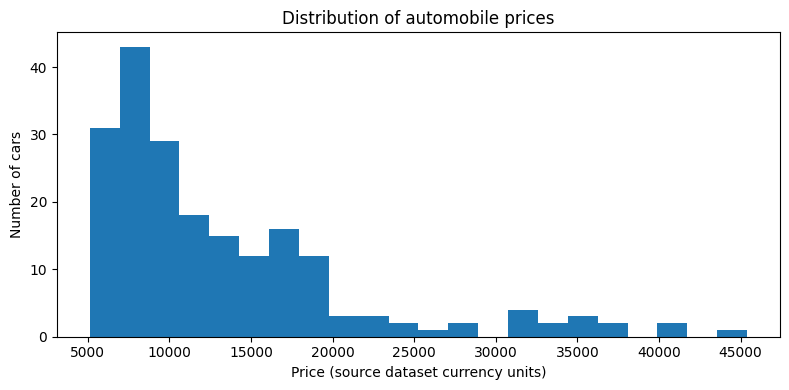

In [5]:
# Price distribution
plt.figure(figsize=(8, 4))
plt.hist(car_data[TARGET], bins=22)
plt.title('Distribution of automobile prices')
plt.xlabel('Price (source dataset currency units)')
plt.ylabel('Number of cars')
plt.tight_layout()
plt.show()

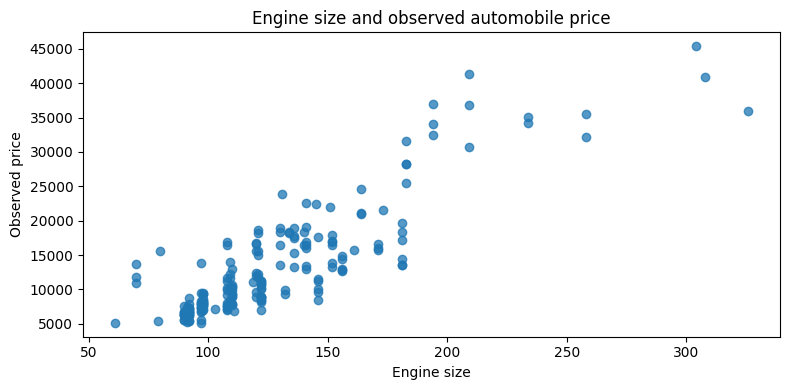

Pearson correlation (engine size / price): 0.872


In [6]:
# Association between engine size and price
plot_data = car_data[['engine-size', TARGET]].dropna()
plt.figure(figsize=(8, 4))
plt.scatter(plot_data['engine-size'], plot_data[TARGET], alpha=0.75)
plt.title('Engine size and observed automobile price')
plt.xlabel('Engine size')
plt.ylabel('Observed price')
plt.tight_layout()
plt.show()

print('Pearson correlation (engine size / price):',
      round(plot_data['engine-size'].corr(plot_data[TARGET]), 3))

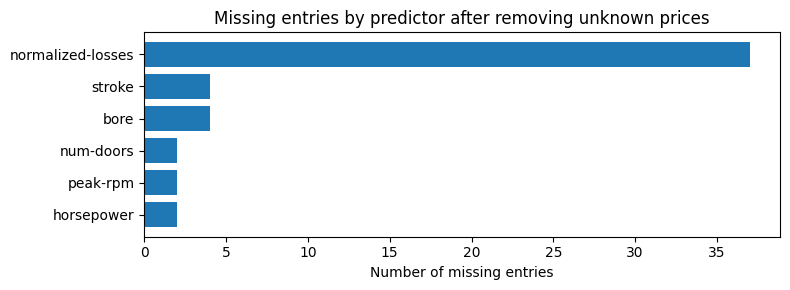

In [7]:
# Missing values by column (columns with observed gaps)
missing_features = car_data[NUMERIC_FEATURES + CATEGORICAL_FEATURES].isna().sum()
missing_features = missing_features[missing_features > 0].sort_values()

if missing_features.empty:
    print('No missing predictor entries remain.')
else:
    plt.figure(figsize=(8, max(3, len(missing_features) * 0.4)))
    plt.barh(missing_features.index, missing_features.values)
    plt.title('Missing entries by predictor after removing unknown prices')
    plt.xlabel('Number of missing entries')
    plt.tight_layout()
    plt.show()

### Task 0.4 | Reserve consistent evaluation data

We split the known-target records into approximately **70% train, 15% validation, 15% test** using a fixed seed. The 70/15/15 split is our proposed experimental design, not a requirement from the Google lab. For the later modelling cells, transformations (median imputation, scaling and categorical encoding) must be fitted **only** on the training portion.

Since this is a small dataset, we will consider cross-validation after the first modelling pass to check whether any apparent improvement is sensitive to the data split.

In [8]:
# Consistent hold-out partitions (shared across all models)
train_validation, test_data = train_test_split(
    car_data, test_size=0.15, random_state=SEED, shuffle=True
)
train_data, validation_data = train_test_split(
    train_validation,
    test_size=0.15 / 0.85,
    random_state=SEED,
    shuffle=True
)

assert len(train_data) + len(validation_data) + len(test_data) == len(car_data)
assert set(train_data.index).isdisjoint(validation_data.index)
assert set(train_data.index).isdisjoint(test_data.index)
assert set(validation_data.index).isdisjoint(test_data.index)

partition_summary = pd.DataFrame({
    'partition': ['train', 'validation', 'test'],
    'rows': [len(train_data), len(validation_data), len(test_data)],
    'mean_price': [train_data[TARGET].mean(),
                   validation_data[TARGET].mean(),
                   test_data[TARGET].mean()],
    'median_price': [train_data[TARGET].median(),
                     validation_data[TARGET].median(),
                     test_data[TARGET].median()]
})
display(partition_summary)

,partition,rows,mean_price,median_price
0,train,139,"12,328.99","10,198.00"
1,validation,31,"12,600.06","10,345.00"
2,test,31,"17,751.65","10,795.00"


### Task 0.5 | Simple reference baseline (not one of the required DNN models)

Before training a neural network, establish a trivial benchmark: always predict the mean training-set price. If a complex model cannot outperform this strategy on validation data, the complex model is not yet useful.

**Important:** Validation metrics are used only to compare candidates. Test-set error metrics will not be used for model selection; preliminary test-set descriptive statistics are shown in Task 0.

In [9]:
# Training-mean baseline: no feature engineering needed
baseline = DummyRegressor(strategy='mean')
baseline.fit(train_data[NUMERIC_FEATURES], train_data[TARGET])

val_predictions = baseline.predict(validation_data[NUMERIC_FEATURES])
val_truth = validation_data[TARGET].to_numpy()

baseline_results = {
    'model': 'Training-mean baseline',
    'validation_MAE': mean_absolute_error(val_truth, val_predictions),
    'validation_RMSE': np.sqrt(mean_squared_error(val_truth, val_predictions)),
    'validation_R2': r2_score(val_truth, val_predictions)
}
display(pd.DataFrame([baseline_results]))

,model,validation_MAE,validation_RMSE,validation_R2
0,Training-mean baseline,"5,301.39","7,208.90",-0.0014


## Task 0 | Interpretation of the observed results

- Original dataset: **205 rows, 26 columns**. Four unknown prices were excluded, leaving **201** labelled rows.
- Missing values include `normalized-losses` (41 original rows), `bore` (4), `stroke` (4), `horsepower` (2), `peak-rpm` (2) and `num-doors` (2). These are not evidence that the true feature values are zero. Fit imputation statistics on the **training** data only.
- Price distribution is right-skewed, with a maximum of **45,400** and median **10,295**. Higher-cost observations can affect RMSE substantially.
- `engine-size` and observed `price` have Pearson correlation **r = 0.872**. This is an association, **not** a causal finding.
- The training-mean model has validation **MAE 5,301.39**, **RMSE 7,208.90** and **R² ≈ 0.00**. Subsequent models should ideally outperform it on the same validation records.
- Preliminary exploration included the test-set mean price (17,751.65 versus 12,328.99 for training). This descriptive inspection limits any claim that the test labels were entirely unseen. **No test-set prediction errors were used for training or model selection.** The independent performance evaluation appears at the end.

These observations come from the saved Task 0 run in this notebook. If the dataset or partition procedure changes, revise this interpretation.


## Task 1 | Numerical DNN without normalisation

**Question asked by the source lab:** Build the strongest feasible regression model using the **15 numerical predictor columns**, with **no feature normalisation**. Explore learning rate, optimiser, network width/depth, batch size and training duration.

**Controlled-design choices:**
1. Train on the same 139 train records and compare on the same 31 validation records used in Task 0.
2. Handle missing numerical entries using a **median fitted exclusively to the train partition** (this is imputation, not scaling).
3. Do **not** standardise, normalise, logarithmically transform, or divide numerical input features in Task 1; also keep price in its original units.
4. Compare three DNN configurations. Gradient clipping mitigates exploding updates; early stopping limits overfitting. Neither operation rescales input features.
5. Rank using **validation RMSE**; report MAE and R² too. The held-out test set is not used in this stage.

The original Estimator examples are implemented here using current TensorFlow/Keras APIs.


In [10]:
# TensorFlow and Keras setup
import time
import warnings
from sklearn.impute import SimpleImputer

try:
    import tensorflow as tf
    from tensorflow import keras
except ImportError as exc:
    raise RuntimeError(
        'TensorFlow is required. Open the notebook in Google Colab, '
        'or install a compatible TensorFlow version before running.'
    ) from exc

keras.utils.set_random_seed(SEED)
print('Training backend: TensorFlow')
print('TensorFlow version:', tf.__version__)
print('Keras version:', keras.__version__)


Training backend: TensorFlow
TensorFlow version: 2.21.0
Keras version: 3.13.2


In [11]:
# Fit missing-value imputation on the TRAIN set; keep raw numeric units
numeric_imputer = SimpleImputer(strategy='median')
X_train_raw = numeric_imputer.fit_transform(train_data[NUMERIC_FEATURES]).astype('float32')
X_val_raw = numeric_imputer.transform(validation_data[NUMERIC_FEATURES]).astype('float32')
y_train = train_data[TARGET].to_numpy(dtype='float32')
y_val = validation_data[TARGET].to_numpy(dtype='float32')

assert X_train_raw.shape == (len(train_data), len(NUMERIC_FEATURES))
assert X_val_raw.shape == (len(validation_data), len(NUMERIC_FEATURES))
assert np.isfinite(X_train_raw).all() and np.isfinite(X_val_raw).all()
assert np.isfinite(y_train).all() and np.isfinite(y_val).all()

print('Training rows:', len(y_train), '| Validation rows:', len(y_val))
print('Numerical predictors:', len(NUMERIC_FEATURES))
print('Feature scaling applied: NO')
print('Example raw feature values (first training row):')
display(pd.DataFrame({'feature': NUMERIC_FEATURES, 'raw_input': X_train_raw[0]}))


Training rows: 139 | Validation rows: 31
Numerical predictors: 15
Feature scaling applied: NO
Example raw feature values (first training row):


,feature,raw_input
0,symboling,0.00
1,normalized-losses,106.00
2,wheel-base,96.50
3,length,167.50
4,width,65.20
5,height,53.30
6,weight,"2,236.00"
7,engine-size,110.00
8,horsepower,86.00
9,peak-rpm,"5,800.00"


### Model architecture and hyperparameters

Each candidate predicts **one continuous price** from the 15 numerical features. We change network architecture, optimiser and batch size deliberately, while keeping the input data partitions and evaluation rules constant. Since several settings change between candidates, this is an **exploratory comparison**, not a clean causal attribution to a single hyperparameter. Task 2.3 examines individual tuning choices in a more controlled comparison.

The model's last layer has one unit and **linear** activation; this is appropriate for regression. ReLU is used in hidden layers. We use MSE loss for training and evaluate with RMSE, MAE and R². Model performance cannot be known until the cells run.


In [12]:
# DNN model builder and training function
from dataclasses import dataclass

@dataclass(frozen=True)
class DNNConfig:
    name: str
    hidden_units: tuple
    optimizer: str
    learning_rate: float
    batch_size: int
    epochs: int = 160


def build_numeric_dnn(config):
    """Build a fresh neural network with no numeric input normalization."""
    layers = [keras.Input(shape=(len(NUMERIC_FEATURES),))]
    layers.extend(
        keras.layers.Dense(units, activation='relu', kernel_initializer='he_normal')
        for units in config.hidden_units
    )
    layers.append(keras.layers.Dense(1, activation='linear'))
    model = keras.Sequential(layers, name=config.name.replace('-', '_'))

    if config.optimizer == 'Adam':
        optimizer = keras.optimizers.Adam(
            learning_rate=config.learning_rate, clipnorm=1.0
        )
    elif config.optimizer == 'RMSprop':
        optimizer = keras.optimizers.RMSprop(
            learning_rate=config.learning_rate, clipnorm=1.0
        )
    else:
        raise ValueError(f'Unrecognised optimizer: {config.optimizer}')

    model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])
    return model


def train_evaluate_numeric_dnn(config):
    """Train on training data only; use validation set only for selection."""
    keras.utils.set_random_seed(SEED)
    model = build_numeric_dnn(config)
    early_stopping = keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=20, restore_best_weights=True
    )

    start_time = time.perf_counter()
    history = model.fit(
        X_train_raw, y_train,
        validation_data=(X_val_raw, y_val),
        epochs=config.epochs,
        batch_size=config.batch_size,
        callbacks=[early_stopping],
        verbose=0,
        shuffle=True,
    )
    elapsed_seconds = time.perf_counter() - start_time
    predictions = model.predict(X_val_raw, verbose=0).reshape(-1)
    if not np.isfinite(predictions).all():
        raise ValueError(f'{config.name} produced non-finite predictions.')

    scores = {
        'model': config.name,
        'optimizer': config.optimizer,
        'learning_rate': config.learning_rate,
        'hidden_units': str(config.hidden_units),
        'batch_size': config.batch_size,
        'epochs_run': len(history.history['loss']),
        'validation_MAE': mean_absolute_error(y_val, predictions),
        'validation_RMSE': np.sqrt(mean_squared_error(y_val, predictions)),
        'validation_R2': r2_score(y_val, predictions),
        'training_seconds': elapsed_seconds,
    }
    return model, history, scores, predictions


In [13]:
# Train three intentionally different unscaled numeric DNNs
TASK1_CONFIGS = [
    DNNConfig('DNN-small-Adam', (16,), 'Adam', 0.0010, 16),
    DNNConfig('DNN-deep-Adam', (32, 16), 'Adam', 0.0008, 16),
    DNNConfig('DNN-deep-RMSprop', (32, 16), 'RMSprop', 0.0005, 32),
]

numeric_models = {}
numeric_histories = {}
numeric_predictions = {}
numeric_results = []

for config in TASK1_CONFIGS:
    try:
        model, history, scores, predictions = train_evaluate_numeric_dnn(config)
        numeric_models[config.name] = model
        numeric_histories[config.name] = history
        numeric_predictions[config.name] = predictions
        numeric_results.append(scores)
        print(f"{config.name}: validation RMSE={scores['validation_RMSE']:,.2f}, "
              f"MAE={scores['validation_MAE']:,.2f}, "
              f"epochs={scores['epochs_run']}")
    except Exception as exc:
        warnings.warn(f'Experiment {config.name} failed: {type(exc).__name__}: {exc}')

if not numeric_results:
    raise RuntimeError('All Task 1 candidates failed; inspect the reported exceptions.')

numeric_comparison = pd.DataFrame(numeric_results).sort_values('validation_RMSE')
display(numeric_comparison.reset_index(drop=True).round({
    'learning_rate': 4, 'validation_MAE': 2, 'validation_RMSE': 2,
    'validation_R2': 3, 'training_seconds': 2,
}))

best_numeric_model_name = str(numeric_comparison.iloc[0]['model'])
best_numeric_val_rmse = float(numeric_comparison.iloc[0]['validation_RMSE'])
baseline_rmse = float(baseline_results['validation_RMSE'])
print('Best numeric model (by validation RMSE):', best_numeric_model_name)
print('Training-mean baseline validation RMSE:', round(baseline_rmse, 2))
print('Best numeric DNN validation RMSE:', round(best_numeric_val_rmse, 2))
print('Improvement over baseline:', f'{100 * (baseline_rmse - best_numeric_val_rmse) / baseline_rmse:.1f}%')



DNN-small-Adam: validation RMSE=3,741.64, MAE=2,632.15, epochs=160
DNN-deep-Adam: validation RMSE=3,668.77, MAE=2,530.96, epochs=160
DNN-deep-RMSprop: validation RMSE=5,502.38, MAE=3,892.61, epochs=160


,model,optimizer,learning_rate,hidden_units,batch_size,epochs_run,validation_MAE,validation_RMSE,validation_R2,training_seconds
0,DNN-deep-Adam,Adam,0.0008,"(32, 16)",16,160,"2,530.96","3,668.77",0.74,17.81
1,DNN-small-Adam,Adam,0.0010,"(16,)",16,160,"2,632.15","3,741.64",0.73,26.38
2,DNN-deep-RMSprop,RMSprop,0.0005,"(32, 16)",32,160,"3,892.61","5,502.38",0.42,16.64


Best numeric model (by validation RMSE): DNN-deep-Adam
Training-mean baseline validation RMSE: 7208.9
Best numeric DNN validation RMSE: 3668.77
Improvement over baseline: 49.1%


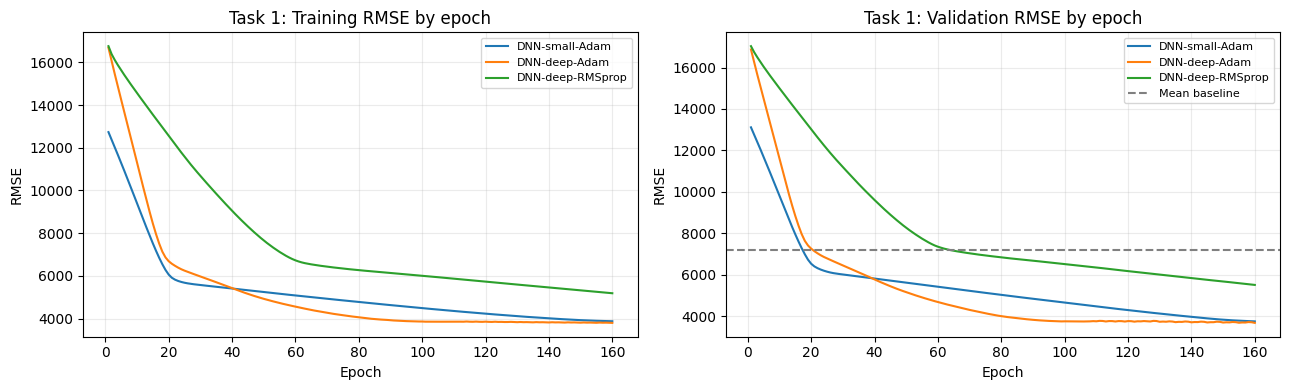

In [14]:
# Learning curves: how training and validation losses evolve
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for model_name, history in numeric_histories.items():
    epochs = np.arange(1, len(history.history['loss']) + 1)
    train_rmse = np.sqrt(np.maximum(np.asarray(history.history['loss']), 0))
    val_rmse = np.sqrt(np.maximum(np.asarray(history.history['val_loss']), 0))
    axes[0].plot(epochs, train_rmse, label=model_name)
    axes[1].plot(epochs, val_rmse, label=model_name)

axes[0].set(title='Task 1: Training RMSE by epoch', xlabel='Epoch', ylabel='RMSE')
axes[1].set(title='Task 1: Validation RMSE by epoch', xlabel='Epoch', ylabel='RMSE')
axes[1].axhline(baseline_rmse, linestyle='--', color='gray', label='Mean baseline')
for axis in axes:
    axis.grid(alpha=0.25)
    axis.legend(fontsize=8)
plt.tight_layout()
plt.show()


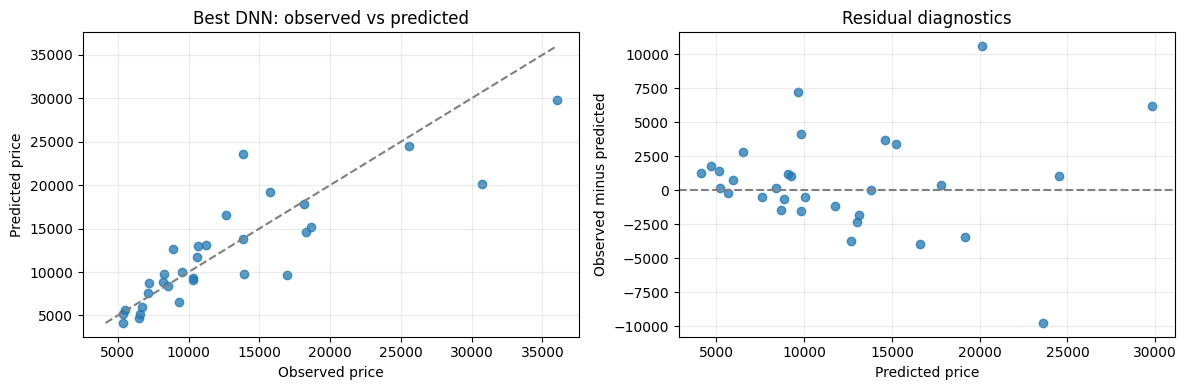

In [15]:
# Prediction diagnostics for the best validation DNN
best_numeric_predictions = numeric_predictions[best_numeric_model_name]
residuals = y_val - best_numeric_predictions

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_val, best_numeric_predictions, alpha=0.75)
plot_min = min(y_val.min(), best_numeric_predictions.min())
plot_max = max(y_val.max(), best_numeric_predictions.max())
axes[0].plot([plot_min, plot_max], [plot_min, plot_max], linestyle='--', color='gray')
axes[0].set(xlabel='Observed price', ylabel='Predicted price', title='Best DNN: observed vs predicted')
axes[1].scatter(best_numeric_predictions, residuals, alpha=0.75)
axes[1].axhline(0, linestyle='--', color='gray')
axes[1].set(xlabel='Predicted price', ylabel='Observed minus predicted', title='Residual diagnostics')
for axis in axes:
    axis.grid(alpha=0.25)
plt.tight_layout()
plt.show()


### Task 1 | Results and interpretation

The following results were recorded in the executed Colab notebook:

| Model | Architecture | Optimiser | Learning rate | Batch size | Validation RMSE | Validation MAE | R² |
|---|---|---|---:|---:|---:|---:|---:|
| Training mean | None | None | — | — | 7,208.90 | 5,301.39 | ≈0.00 |
| DNN-small-Adam | (16,) | Adam | 0.0010 | 16 | 3,741.64 | 2,632.15 | 0.73 |
| **DNN-deep-Adam** | **(32, 16)** | **Adam** | **0.0008** | **16** | **3,668.77** | **2,530.96** | **0.74** |
| DNN-deep-RMSprop | (32, 16) | RMSprop | 0.0005 | 32 | 5,502.38 | 3,892.61 | 0.42 |

- On **31 validation observations**, the lowest RMSE was 3,668.77 for DNN-deep-Adam, **49.1% lower than the training-mean baseline**.
- The best and second-best DNNs differ in RMSE by only **72.87** (approximately **2.0%** of the larger RMSE); a single split cannot establish a robust advantage.
- Training/validation RMSE generally fell during 160 epochs. The plots do **not** show a clear, persistent overfitting gap, although a single learning curve cannot rule out overfitting.
- Some higher-priced cars have large residuals (around ±10,000), so overall RMSE is affected by relatively few observations.
- The three candidates vary **several** settings simultaneously; observed differences cannot be attributed causally to one hyperparameter.

**Next hypothesis:** Standardising the same numerical predictors may alter neural-network optimisation. To isolate this change initially, Task 2 first holds each model configuration and the target variable unchanged. We will look at both whether RMSE improves and whether training dynamics improve. Test-set errors are not used for model selection.

## Task 2 | Normalisation and hyperparameter tuning
### 2.1 | Feature standardisation

**Source lab requirement:** Retrain the regression model after normalising numerical features. We use `StandardScaler` (training-set mean and standard deviation), rather than scaling using the whole dataset.

**Controlled experiment:** Every Task 1 candidate is retrained with identical hidden layers, optimiser, learning rate, batch size, maximum epochs and evaluation split. **Only the numerical input representation changes.** The target `price` is still in its original units. We fit the imputer and scaler on training data only, preventing information leakage.

**Interpretation warning:** Standardising input features is not guaranteed to improve RMSE under fixed optimisation settings, especially with a large unscaled target and only 160 epochs. If results worsen, that is a finding to investigate through controlled hyperparameter tuning, **not** a reason to discard it.

In [16]:
# Feature standardisation fitted only on training rows
from sklearn.preprocessing import StandardScaler

numeric_standardizer = StandardScaler()
X_train_scaled = numeric_standardizer.fit_transform(X_train_raw).astype('float32')
X_val_scaled = numeric_standardizer.transform(X_val_raw).astype('float32')

assert X_train_scaled.shape == X_train_raw.shape
assert X_val_scaled.shape == X_val_raw.shape
assert np.isfinite(X_train_scaled).all() and np.isfinite(X_val_scaled).all()
assert np.allclose(X_train_scaled.mean(axis=0), 0.0, atol=1e-5)

scaling_audit = pd.DataFrame({
    'feature': NUMERIC_FEATURES,
    'train_original_mean': X_train_raw.mean(axis=0),
    'train_original_std': X_train_raw.std(axis=0),
    'train_scaled_mean': X_train_scaled.mean(axis=0),
    'train_scaled_std': X_train_scaled.std(axis=0),
})
print('Scaling method: StandardScaler | Fitted to TRAIN ONLY')
print('Training rows:', len(X_train_scaled), '| Validation rows:', len(X_val_scaled))
print('The prediction target PRICE has NOT been scaled.')
display(scaling_audit.round(3))

Scaling method: StandardScaler | Fitted to TRAIN ONLY
Training rows: 139 | Validation rows: 31
The prediction target PRICE has NOT been scaled.


,feature,train_original_mean,train_original_std,train_scaled_mean,train_scaled_std
0,symboling,0.83,1.26,0.00,1.00
1,normalized-losses,119.86,33.00,0.00,1.00
2,wheel-base,98.59,5.88,-0.00,1.00
3,length,173.79,11.86,0.00,1.00
4,width,65.79,2.01,0.00,1.00
5,height,53.78,2.49,-0.00,1.00
6,weight,"2,536.59",473.30,0.00,1.00
7,engine-size,123.73,37.13,-0.00,1.00
8,horsepower,101.13,33.20,0.00,1.00
9,peak-rpm,"5,121.22",469.96,0.00,1.00


In [17]:
# Reusable runner for paired standardised-input experiments
# Keeps the model architecture and training rules from Task 1 unchanged.

def train_evaluate_scaled_dnn(config):
    """Train a new DNN on scaled numerical inputs and assess it on validation rows."""
    keras.utils.set_random_seed(SEED)
    model = build_numeric_dnn(config)
    early_stopping = keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=20, restore_best_weights=True
    )
    start_time = time.perf_counter()
    history = model.fit(
        X_train_scaled, y_train,
        validation_data=(X_val_scaled, y_val),
        epochs=config.epochs,
        batch_size=config.batch_size,
        callbacks=[early_stopping],
        verbose=0,
        shuffle=True,
    )
    elapsed_seconds = time.perf_counter() - start_time
    predictions = model.predict(X_val_scaled, verbose=0).reshape(-1)
    if not np.isfinite(predictions).all():
        raise ValueError(f'{config.name} returned non-finite predictions')
    metrics = {
        'model': config.name,
        'optimizer': config.optimizer,
        'learning_rate': config.learning_rate,
        'hidden_units': str(config.hidden_units),
        'batch_size': config.batch_size,
        'epochs_run': len(history.history['loss']),
        'validation_MAE': float(mean_absolute_error(y_val, predictions)),
        'validation_RMSE': float(np.sqrt(mean_squared_error(y_val, predictions))),
        'validation_R2': float(r2_score(y_val, predictions)),
        'training_seconds': float(elapsed_seconds),
    }
    return model, history, metrics, predictions

In [18]:
# Run matched Task 2 models, compare them with Task 1
scaled_models, scaled_histories, scaled_predictions = {}, {}, {}
scaled_results = []

for config in TASK1_CONFIGS:
    try:
        model, history, scores, predictions = train_evaluate_scaled_dnn(config)
        scaled_models[config.name] = model
        scaled_histories[config.name] = history
        scaled_predictions[config.name] = predictions
        scaled_results.append(scores)
        print(f"{config.name}: scaled validation RMSE={scores['validation_RMSE']:,.2f}, "
              f"MAE={scores['validation_MAE']:,.2f}, epochs={scores['epochs_run']}")
    except Exception as exc:
        warnings.warn(f"Task 2 model {config.name} failed: {type(exc).__name__}: {exc}")

if not scaled_results:
    raise RuntimeError('All standardised-input models failed; inspect the warnings.')

scaled_comparison = pd.DataFrame(scaled_results).sort_values('validation_RMSE')
print('Task 2: model metrics (learning rates shown with proper precision)')
display(scaled_comparison.round({'learning_rate': 5, 'validation_MAE': 2, 'validation_RMSE': 2, 'validation_R2': 3, 'training_seconds': 2}).reset_index(drop=True))

paired_comparison = (numeric_comparison[['model', 'validation_RMSE','validation_MAE', 'validation_R2']]
    .rename(columns={'validation_RMSE':'raw_RMSE', 'validation_MAE':'raw_MAE', 'validation_R2':'raw_R2'})
    .merge(scaled_comparison[['model', 'validation_RMSE','validation_MAE','validation_R2']]
       .rename(columns={'validation_RMSE':'scaled_RMSE', 'validation_MAE':'scaled_MAE','validation_R2':'scaled_R2'}),
       on='model', how='inner'))
paired_comparison['RMSE_change_pct'] = (
    100.0 * (paired_comparison['scaled_RMSE'] - paired_comparison['raw_RMSE'])
    / paired_comparison['raw_RMSE']
)
print('Matched-configuration comparison (NEGATIVE RMSE change = improvement):')
display(paired_comparison.round(2))
print('Best standardised-input model:', scaled_comparison.iloc[0]['model'])


DNN-small-Adam: scaled validation RMSE=14,396.74, MAE=12,501.27, epochs=160


DNN-deep-Adam: scaled validation RMSE=12,997.20, MAE=11,262.90, epochs=160


DNN-deep-RMSprop: scaled validation RMSE=14,428.24, MAE=12,519.79, epochs=160
Task 2: model metrics (learning rates shown with proper precision)


,model,optimizer,learning_rate,hidden_units,batch_size,epochs_run,validation_MAE,validation_RMSE,validation_R2,training_seconds
0,DNN-deep-Adam,Adam,0.0008,"(32, 16)",16,160,"11,262.90","12,997.20",-2.25,17.89
1,DNN-small-Adam,Adam,0.0010,"(16,)",16,160,"12,501.27","14,396.74",-2.99,16.26
2,DNN-deep-RMSprop,RMSprop,0.0005,"(32, 16)",32,160,"12,519.79","14,428.24",-3.01,15.09


Matched-configuration comparison (NEGATIVE RMSE change = improvement):


,model,raw_RMSE,raw_MAE,raw_R2,scaled_RMSE,scaled_MAE,scaled_R2,RMSE_change_pct
0,DNN-deep-Adam,"3,668.77","2,530.96",0.74,"12,997.20","11,262.90",-2.26,254.27
1,DNN-small-Adam,"3,741.64","2,632.15",0.73,"14,396.74","12,501.27",-2.99,284.77
2,DNN-deep-RMSprop,"5,502.38","3,892.61",0.42,"14,428.24","12,519.79",-3.01,162.22


Best standardised-input model: DNN-deep-Adam


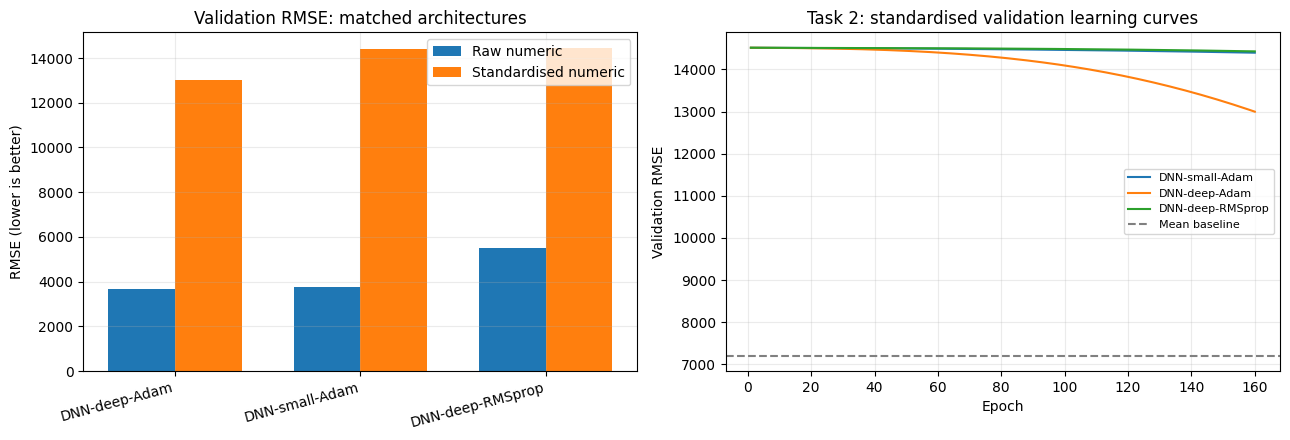

In [19]:
# Visualise changes caused by feature scaling
if not paired_comparison.empty:
    positions = np.arange(len(paired_comparison))
    width = 0.36
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    axes[0].bar(positions - width/2, paired_comparison['raw_RMSE'], width, label='Raw numeric')
    axes[0].bar(positions + width/2, paired_comparison['scaled_RMSE'], width, label='Standardised numeric')
    axes[0].set_xticks(positions, paired_comparison['model'], rotation=15, ha='right')
    axes[0].set(title='Validation RMSE: matched architectures', ylabel='RMSE (lower is better)')
    axes[0].legend()

    for name, history in scaled_histories.items():
        epochs = np.arange(1, len(history.history['val_loss']) + 1)
        val_rmse = np.sqrt(np.maximum(0, np.asarray(history.history['val_loss'])))
        axes[1].plot(epochs, val_rmse, label=name)
    axes[1].axhline(baseline_rmse, linestyle='--', color='gray', label='Mean baseline')
    axes[1].set(title='Task 2: standardised validation learning curves', xlabel='Epoch', ylabel='Validation RMSE')
    axes[1].legend(fontsize=8)
    for axis in axes:
        axis.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

### 2.2 | Target-scaling control

A neural network trained with **standardised inputs but raw price labels** may learn slowly: its initial outputs are near zero, while target values are in the thousands. This can obscure the benefit of feature standardisation under a fixed 160-epoch budget. We therefore run an **additional matched pair** as a sensitivity check:

- Both candidates use the **same DNN-deep-Adam configuration**, the same data, the same standardised `price` labels and the same random seed.
- The only factor that changes **within this pair** is whether the numerical inputs are raw or standardised.
- We standardise `price` using the **training** labels only. Predictions are converted back to the original price units *before* computing MAE, RMSE and R².

This pair must be discussed separately from the original Task 1 models because its **target-preprocessing procedure differs**. Its purpose is to isolate the feature-scaling effect under more suitable optimisation conditions.

In [20]:
# Paired experiment with the SAME target standardisation on both sides
price_standardizer = StandardScaler()
y_train_standardized = price_standardizer.fit_transform(y_train.reshape(-1, 1)).ravel()
y_val_standardized = price_standardizer.transform(y_val.reshape(-1, 1)).ravel()

assert np.isfinite(y_train_standardized).all()
assert np.isfinite(y_val_standardized).all()

pair_config = next(config for config in TASK1_CONFIGS if config.name == 'DNN-deep-Adam')
paired_target_models, paired_target_histories, paired_target_scores = {}, {}, []

for input_name, x_train, x_val in [
    ('Raw X / standardised y', X_train_raw, X_val_raw),
    ('Standardised X / standardised y', X_train_scaled, X_val_scaled),
]:
    keras.utils.set_random_seed(SEED)
    paired_model = build_numeric_dnn(pair_config)
    callback = keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=20, restore_best_weights=True
    )
    start_time = time.perf_counter()
    paired_history = paired_model.fit(
        x_train, y_train_standardized,
        validation_data=(x_val, y_val_standardized),
        epochs=pair_config.epochs,
        batch_size=pair_config.batch_size,
        callbacks=[callback],
        shuffle=True,
        verbose=0,
    )
    run_time = time.perf_counter() - start_time
    prediction_z = paired_model.predict(x_val, verbose=0).reshape(-1, 1)
    predicted_prices = price_standardizer.inverse_transform(prediction_z).ravel()
    if not np.isfinite(predicted_prices).all():
        raise ValueError(f'{input_name} generated invalid predicted prices')

    paired_target_models[input_name] = paired_model
    paired_target_histories[input_name] = paired_history
    paired_target_scores.append({
        'input_representation': input_name,
        'validation_RMSE': float(np.sqrt(mean_squared_error(y_val, predicted_prices))),
        'validation_MAE': float(mean_absolute_error(y_val, predicted_prices)),
        'validation_R2': float(r2_score(y_val, predicted_prices)),
        'epochs_run': len(paired_history.history['loss']),
        'training_seconds': run_time,
    })

paired_target_table = pd.DataFrame(paired_target_scores)
print('Control: SAME standardised target, architecture and training rules; only X changes')
display(paired_target_table.round(2))
raw_target_pair_rmse = paired_target_table.iloc[0]['validation_RMSE']
scaled_target_pair_rmse = paired_target_table.iloc[1]['validation_RMSE']
print(f'Change in RMSE due to input scaling within this matched pair: '
      f'{scaled_target_pair_rmse-raw_target_pair_rmse:+,.2f} '
      f'({100*(scaled_target_pair_rmse-raw_target_pair_rmse)/raw_target_pair_rmse:+.1f}%)')


Control: SAME standardised target, architecture and training rules; only X changes


,input_representation,validation_RMSE,validation_MAE,validation_R2,epochs_run,training_seconds
0,Raw X / standardised y,"38,198.16","33,973.21",-27.12,144,15.41
1,Standardised X / standardised y,"3,713.13","2,704.06",0.73,55,7.65


Change in RMSE due to input scaling within this matched pair: -34,485.04 (-90.3%)


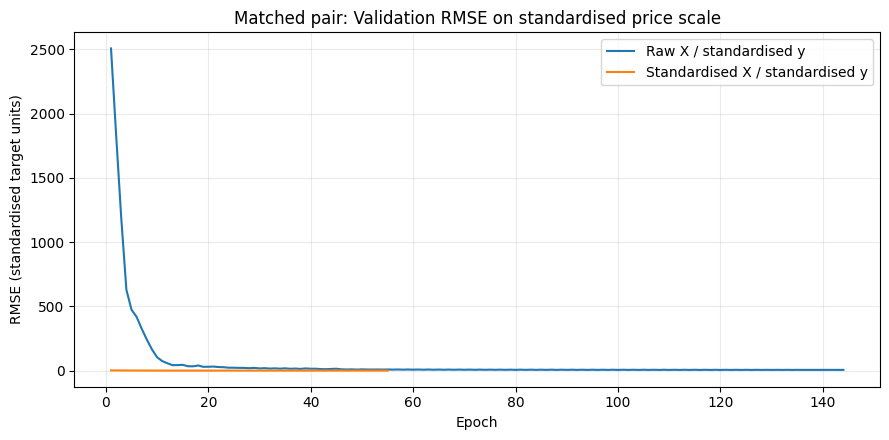

In [21]:
# Learning curves for the target-standardised matched pair
plt.figure(figsize=(9, 4.5))
for name, history in paired_target_histories.items():
    # The plotted loss uses standardised target units; the output table above
    # always uses ORIGINAL price units for the assessment's interpretation.
    learning_curve = np.sqrt(np.maximum(np.asarray(history.history['val_loss']), 0))
    plt.plot(np.arange(1, len(learning_curve)+1), learning_curve, label=name)
plt.title('Matched pair: Validation RMSE on standardised price scale')
plt.xlabel('Epoch')
plt.ylabel('RMSE (standardised target units)')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Task 2.1–2.2 | Results and interpretation

**Input-only standardisation (2.1):** With the *original unstandardised price target* and a fixed training configuration, standardising numerical inputs worsened validation RMSE for all three DNNs: Deep Adam **3,668.77 → 12,997.20**, Small Adam **3,741.64 → 14,396.74**, and Deep RMSprop **5,502.38 → 14,428.24**. The scaled-input models did not converge sufficiently under this particular learning-rate/epoch combination; these results do **not** establish that standardisation is intrinsically harmful.

**Matched target-scale experiment (2.2):** When **both** paired models used the same training-set-standardised price labels, the unscaled-input model produced RMSE **38,198.16**, whereas the scaled-input model produced **3,713.13** (both errors reported after inverse-transforming to original price units). Input standardisation substantially improved optimisation in *that pair*. The very poor raw-input member should be treated as a sign of training instability, not as a representative performance baseline.

**Limitation:** Target preprocessing differs between Task 1 and Section 2.2, so cross-task RMSE differences cannot be causally attributed to input scaling alone. Results are based on a small fixed validation set and may vary across seeds/splits. The held-out test set has not been evaluated.

### 2.3 | Hyperparameter tuning after standardisation

**Why this is needed.** Section 2.1 held the Task 1 settings constant, which isolates the effect of input scaling, but does not show whether those settings remain appropriate after normalisation. Section 2.2 then held target scaling constant. Here we tune the **standardised-input and standardised-target** DNN on the same 139 training / 31 validation observations.

- **Control:** the previously executed deep-Adam `(32, 16)` network, learning rate `0.0008`, batch size `16` (Section 2.2).
- **One-factor variations:** lower learning rate, higher learning rate, larger batch, smaller architecture, alternative optimiser. We change exactly one tuning factor relative to the control in each candidate.
- **Evaluation:** validation MAE, RMSE, R² in *original price units*, epochs actually run and training seconds. Every candidate uses the same `SEED`, maximum 160 epochs, early stopping, and the **same training-fitted scalers**. The held-out TEST observations are not used.

*Evaluation boundary:* The additional tuning experiment was run after the Ridge cross-validation and test evaluation had been recorded. Accordingly, these DNN results remain **validation-only**; the previously reported Ridge choice and independent test result are not revised.


In [22]:
# Task 2.3 | Controlled tuning on the same standardised X and y
# The reference run is the existing Task 2.2 experiment: do not train it twice.
reference_row = paired_target_table.loc[
    paired_target_table['input_representation'] == 'Standardised X / standardised y'
]
assert len(reference_row) == 1, 'Run Task 2.2 before this section.'
reference = reference_row.iloc[0]

task2_tuning_configs = [
    # Compare each configuration with the deep Adam control: (32, 16), lr=0.0008, batch=16.
    DNNConfig('T2-LR-low', (32, 16), 'Adam', 0.0002, 16, 160),
    DNNConfig('T2-LR-high', (32, 16), 'Adam', 0.0030, 16, 160),
    DNNConfig('T2-Batch-32', (32, 16), 'Adam', 0.0008, 32, 160),
    DNNConfig('T2-Shallow', (16,), 'Adam', 0.0008, 16, 160),
    DNNConfig('T2-RMSprop', (32, 16), 'RMSprop', 0.0008, 16, 160),
]

task2_tuning_records = [{
    'model': 'T2-Control (from Task 2.2)', 'changed_factor': 'Reference',
    'hidden_units': '(32, 16)', 'optimizer': 'Adam',
    'learning_rate': 0.0008, 'batch_size': 16,
    'epochs_run': int(reference['epochs_run']),
    'validation_RMSE': float(reference['validation_RMSE']),
    'validation_MAE': float(reference['validation_MAE']),
    'validation_R2': float(reference['validation_R2']),
    'training_seconds': float(reference['training_seconds']),
}]

task2_change_names = {
    'T2-LR-low': 'Learning rate',
    'T2-LR-high': 'Learning rate',
    'T2-Batch-32': 'Batch size',
    'T2-Shallow': 'Network architecture',
    'T2-RMSprop': 'Optimizer',
}

def run_task2_tuning(config):
    """Evaluate one DNN, inverse-transform prices, and report full error/time metrics."""
    keras.utils.set_random_seed(SEED)
    model = build_numeric_dnn(config)
    stopper = keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=20, restore_best_weights=True
    )
    started = time.perf_counter()
    history = model.fit(
        X_train_scaled, y_train_standardized,
        validation_data=(X_val_scaled, y_val_standardized),
        epochs=config.epochs, batch_size=config.batch_size,
        callbacks=[stopper], shuffle=True, verbose=0,
    )
    elapsed = time.perf_counter() - started
    pred_z = model.predict(X_val_scaled, verbose=0).reshape(-1, 1)
    predicted_price = price_standardizer.inverse_transform(pred_z).ravel()
    if not np.isfinite(predicted_price).all():
        raise ValueError(f'Non-finite predictions in {config.name}')
    record = {
        'model': config.name, 'changed_factor': task2_change_names[config.name],
        'hidden_units': str(config.hidden_units), 'optimizer': config.optimizer,
        'learning_rate': config.learning_rate, 'batch_size': config.batch_size,
        'epochs_run': len(history.history['loss']),
        'validation_RMSE': float(np.sqrt(mean_squared_error(y_val, predicted_price))),
        'validation_MAE': float(mean_absolute_error(y_val, predicted_price)),
        'validation_R2': float(r2_score(y_val, predicted_price)),
        'training_seconds': float(elapsed),
    }
    return record, history

task2_tuning_histories = {}
for cfg in task2_tuning_configs:
    result, fitted_history = run_task2_tuning(cfg)
    task2_tuning_records.append(result)
    task2_tuning_histories[cfg.name] = fitted_history
    print(f"{cfg.name}: RMSE={result['validation_RMSE']:,.2f}; "
          f"epochs={result['epochs_run']}; seconds={result['training_seconds']:.1f}")

task2_tuning_table = pd.DataFrame(task2_tuning_records).sort_values(
    'validation_RMSE', ascending=True
).reset_index(drop=True)
assert len(task2_tuning_table) == 6
print('Task 2.3: validation results in ORIGINAL price units; smaller RMSE is better')
display(task2_tuning_table.round({
    'learning_rate': 4, 'validation_RMSE': 2,
    'validation_MAE': 2, 'validation_R2': 3, 'training_seconds': 2,
}))


T2-LR-low: RMSE=3,817.01; epochs=160; seconds=16.5
T2-LR-high: RMSE=3,895.01; epochs=26; seconds=3.8
T2-Batch-32: RMSE=3,434.38; epochs=80; seconds=8.3
T2-Shallow: RMSE=4,487.59; epochs=160; seconds=15.9
T2-RMSprop: RMSE=3,558.41; epochs=77; seconds=8.9
Task 2.3: validation results in ORIGINAL price units; smaller RMSE is better


,model,changed_factor,hidden_units,optimizer,learning_rate,batch_size,epochs_run,validation_RMSE,validation_MAE,validation_R2,training_seconds
0,T2-Batch-32,Batch size,"(32, 16)",Adam,0.0008,32,80,"3,434.38","2,560.38",0.77,8.26
1,T2-RMSprop,Optimizer,"(32, 16)",RMSprop,0.0008,16,77,"3,558.41","2,453.57",0.76,8.87
2,T2-Control (from Task 2.2),Reference,"(32, 16)",Adam,0.0008,16,55,"3,713.13","2,704.06",0.73,7.65
3,T2-LR-low,Learning rate,"(32, 16)",Adam,0.0002,16,160,"3,817.01","2,691.93",0.72,16.51
4,T2-LR-high,Learning rate,"(32, 16)",Adam,0.0030,16,26,"3,895.01","2,751.13",0.71,3.78
5,T2-Shallow,Network architecture,"(16,)",Adam,0.0008,16,160,"4,487.59","2,421.32",0.61,15.89


**Section 2.3 results (validation only).** Increasing batch size from 16 to 32 reduced RMSE from **3,713.13** to **3,434.38** (7.5%) with the same `(32, 16)` Adam network, learning rate `0.0008` and target scaling. RMSprop reached **3,558.41**; a shallower network reached **4,487.59**. Under these settings, a batch-size change mattered more than increasing network complexity. These comparisons are based on one 31-record validation split; we do not infer general superiority. The previously frozen **Ridge-only 5-fold CV choice** and one-time test outcome are unchanged.

**Comparison basis:** Every tuning candidate differs from the control in one factor. Training time and epochs are reported alongside RMSE; the 31-record validation set does not establish statistical superiority. The final Ridge model was selected separately through five-fold cross-validation.

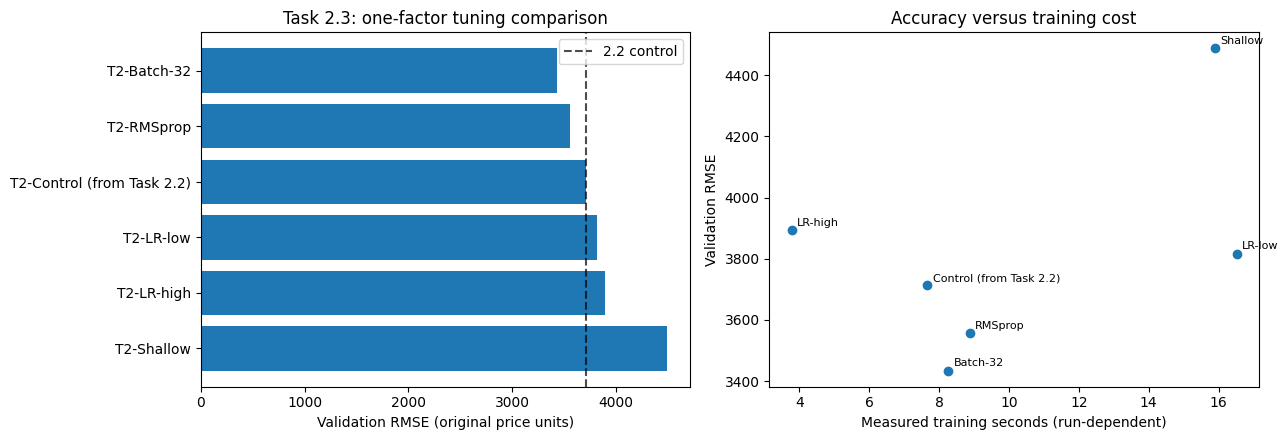

Tuning effect against the original paired, scaled-input control:


,model,changed_factor,learning_rate,batch_size,validation_RMSE,delta_RMSE_vs_control,epochs_run,training_seconds
0,T2-Batch-32,Batch size,0.0008,32,"3,434.38",-278.75,80,8.26
1,T2-RMSprop,Optimizer,0.0008,16,"3,558.41",-154.72,77,8.87
2,T2-Control (from Task 2.2),Reference,0.0008,16,"3,713.13",0.00,55,7.65
3,T2-LR-low,Learning rate,0.0002,16,"3,817.01",103.88,160,16.51
4,T2-LR-high,Learning rate,0.0030,16,"3,895.01",181.88,26,3.78
5,T2-Shallow,Network architecture,0.0008,16,"4,487.59",774.46,160,15.89


Lowest Task 2.3 validation RMSE: T2-Batch-32
Tuning results use the validation set; final Ridge selection is evaluated separately.


In [23]:
# Task 2.3 | Plot model tuning results and quantify improvements over the reference
control_rmse = float(task2_tuning_table.loc[
    task2_tuning_table['model'] == 'T2-Control (from Task 2.2)', 'validation_RMSE'
].iloc[0])
ordered = task2_tuning_table.sort_values('validation_RMSE', ascending=True).copy()
ordered['delta_RMSE_vs_control'] = ordered['validation_RMSE'] - control_rmse

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].barh(ordered['model'][::-1], ordered['validation_RMSE'][::-1])
axes[0].axvline(control_rmse, linestyle='--', color='black', alpha=0.7, label='2.2 control')
axes[0].set_xlabel('Validation RMSE (original price units)')
axes[0].set_title('Task 2.3: one-factor tuning comparison')
axes[0].legend()

axes[1].scatter(ordered['training_seconds'], ordered['validation_RMSE'])
for _, row in ordered.iterrows():
    axes[1].annotate(row['model'].replace('T2-', ''),
                     (row['training_seconds'], row['validation_RMSE']),
                     xytext=(4, 3), textcoords='offset points', fontsize=8)
axes[1].set_xlabel('Measured training seconds (run-dependent)')
axes[1].set_ylabel('Validation RMSE')
axes[1].set_title('Accuracy versus training cost')
plt.tight_layout()
plt.show()

print('Tuning effect against the original paired, scaled-input control:')
display(ordered[['model', 'changed_factor', 'learning_rate', 'batch_size',
                 'validation_RMSE', 'delta_RMSE_vs_control',
                 'epochs_run', 'training_seconds']].round({
                     'learning_rate': 4, 'validation_RMSE': 2,
                     'delta_RMSE_vs_control': 2, 'training_seconds': 2,
                 }))
print('Lowest Task 2.3 validation RMSE:', ordered.iloc[0]['model'])
print('Tuning results use the validation set; final Ridge selection is evaluated separately.')


## Task 3 | Categorical-only price prediction

**Question:** How informative are the 10 categorical inputs when **all numeric predictors are excluded**?

We perform **train-only** missing-value imputation (most frequent category), fit a one-hot encoder on **training categories only**, and transform the unchanged validation set. Unseen validation categories are encoded as zeros (`handle_unknown='ignore'`) rather than causing a failure. Our models are:

- **Ridge (α=1)** and **Ridge (α=30)**: transparent, regularised linear regression alternatives.
- **Categorical DNN-small** and **Categorical DNN-deep**: neural networks trained on one-hot vectors. We standardise *training price labels* to stabilise neural-network optimisation, then inverse-transform predictions into the original currency units for all reported metrics.

All models predict the same price outcome and use identical data partitions and evaluation metrics (MAE, RMSE, R²). For accuracy comparisons, compare **validation errors in original price units**. Test prediction errors are reserved for the final evaluation; descriptive statistics were inspected in Task 0.

In [24]:
# Preprocess 10 categorical variables (TRAIN-ONLY fitting)
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

assert len(CATEGORICAL_FEATURES) == 10
cat_imputer = SimpleImputer(strategy='most_frequent')
cat_train_labels = cat_imputer.fit_transform(train_data[CATEGORICAL_FEATURES])
cat_val_labels = cat_imputer.transform(validation_data[CATEGORICAL_FEATURES])

# sklearn 1.2+ uses sparse_output; older versions use sparse.
try:
    cat_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False, dtype=np.float32)
except TypeError:
    cat_encoder = OneHotEncoder(handle_unknown='ignore', sparse=False, dtype=np.float32)

X_train_cat = cat_encoder.fit_transform(cat_train_labels).astype('float32')
X_val_cat = cat_encoder.transform(cat_val_labels).astype('float32')
cat_encoded_names = cat_encoder.get_feature_names_out(CATEGORICAL_FEATURES)

assert X_train_cat.shape[0] == len(y_train)
assert X_val_cat.shape[0] == len(y_val)
assert X_train_cat.shape[1] == X_val_cat.shape[1] == len(cat_encoded_names)
assert np.isfinite(X_train_cat).all() and np.isfinite(X_val_cat).all()

print('Original categorical inputs:', len(CATEGORICAL_FEATURES))
print('One-hot encoded features:', X_train_cat.shape[1])
print('Training / validation observations:', len(X_train_cat), '/', len(X_val_cat))
print('Numerical input features included:', 0)
print('Example encoded feature names:', list(cat_encoded_names[:15]))
display(pd.DataFrame({'feature': CATEGORICAL_FEATURES,
                      'distinct_categories_in_train': [len(c) for c in cat_encoder.categories_]}))

Original categorical inputs: 10
One-hot encoded features: 58
Training / validation observations: 139 / 31
Numerical input features included: 0
Example encoded feature names: ['make_alfa-romero', 'make_audi', 'make_bmw', 'make_chevrolet', 'make_dodge', 'make_honda', 'make_isuzu', 'make_jaguar', 'make_mazda', 'make_mercedes-benz', 'make_mercury', 'make_mitsubishi', 'make_nissan', 'make_peugot', 'make_plymouth']


,feature,distinct_categories_in_train
0,make,22
1,fuel-type,2
2,aspiration,2
3,num-doors,2
4,body-style,5
5,drive-wheels,3
6,engine-location,2
7,engine-type,6
8,num-cylinders,6
9,fuel-system,8


In [25]:
# Create a common categorical-model evaluation utility
from sklearn.linear_model import Ridge

def evaluate_category_model(name, predictions, elapsed=None, model_type=None, settings=None):
    """Calculate comparable original-price validation metrics; fail on invalid outputs."""
    predicted = np.asarray(predictions, dtype='float64').reshape(-1)
    if predicted.shape != y_val.shape or not np.isfinite(predicted).all():
        raise ValueError(f'{name}: invalid prediction shape or non-finite predictions')
    return {
        'model': name,
        'model_type': model_type or 'unknown',
        'settings': settings or '',
        'validation_MAE': float(mean_absolute_error(y_val, predicted)),
        'validation_RMSE': float(np.sqrt(mean_squared_error(y_val, predicted))),
        'validation_R2': float(r2_score(y_val, predicted)),
        'training_seconds': elapsed,
    }

category_results = []
category_predictions = {}
category_models = {}
category_histories = {}

# Models use only one-hot categorical variables; no numerical inputs.
for alpha in (1.0, 30.0):
    start = time.perf_counter()
    regressor = Ridge(alpha=alpha)
    regressor.fit(X_train_cat, y_train)
    elapsed = time.perf_counter() - start
    model_name = f'Categorical-Ridge-alpha{alpha:g}'
    predictions = regressor.predict(X_val_cat).reshape(-1)
    category_models[model_name] = regressor
    category_predictions[model_name] = predictions
    category_results.append(evaluate_category_model(
        model_name, predictions, elapsed, 'Ridge', f'alpha={alpha:g}'
    ))
    print(f'{model_name}: validation RMSE={category_results[-1]["validation_RMSE"]:,.2f}')

Categorical-Ridge-alpha1: validation RMSE=3,264.88
Categorical-Ridge-alpha30: validation RMSE=4,506.15


In [26]:
# Train categorical-only DNNs with a consistent target scale
# Standardise TARGET for neural-network optimisation, using TRAINING labels only.
category_target_scaler = StandardScaler()
category_y_train = category_target_scaler.fit_transform(y_train.reshape(-1, 1)).reshape(-1)
category_y_val = category_target_scaler.transform(y_val.reshape(-1, 1)).reshape(-1)

CATEGORY_DNN_CONFIGS = [
    DNNConfig('Categorical-DNN-small', (16,), 'Adam', 0.002, 16, 200),
    DNNConfig('Categorical-DNN-deep', (32, 16), 'Adam', 0.001, 16, 200),
]

def build_categorical_dnn(config, number_features):
    """Build a dedicated categorical regression network (no numeric inputs)."""
    layers = [keras.Input(shape=(number_features,))]
    layers += [keras.layers.Dense(size, activation='relu', kernel_initializer='he_normal')
               for size in config.hidden_units]
    layers += [keras.layers.Dense(1, activation='linear')]
    if config.optimizer != 'Adam':
        raise ValueError('The categorical DNN experiment requires Adam')
    model = keras.Sequential(layers, name=config.name.replace('-', '_'))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=config.learning_rate),
                  loss='mse', metrics=['mae'])
    return model

for config in CATEGORY_DNN_CONFIGS:
    keras.utils.set_random_seed(SEED)
    model = build_categorical_dnn(config, X_train_cat.shape[1])
    stopping = keras.callbacks.EarlyStopping(monitor='val_loss', patience=25,
                                              restore_best_weights=True)
    start = time.perf_counter()
    history = model.fit(
        X_train_cat, category_y_train,
        validation_data=(X_val_cat, category_y_val),
        epochs=config.epochs, batch_size=config.batch_size,
        callbacks=[stopping], shuffle=True, verbose=0
    )
    elapsed = time.perf_counter() - start
    prediction_z = model.predict(X_val_cat, verbose=0).reshape(-1, 1)
    predictions = category_target_scaler.inverse_transform(prediction_z).reshape(-1)
    category_models[config.name] = model
    category_histories[config.name] = history
    category_predictions[config.name] = predictions
    category_results.append(evaluate_category_model(
        config.name, predictions, elapsed, 'DNN',
        f'hidden={config.hidden_units}; lr={config.learning_rate}; '
        f'batch={config.batch_size}; epochs_run={len(history.history["loss"])}'
    ))
    print(f'{config.name}: validation RMSE={category_results[-1]["validation_RMSE"]:,.2f}; '
          f'epochs={len(history.history["loss"])}')

Categorical-DNN-small: validation RMSE=2,577.88; epochs=56
Categorical-DNN-deep: validation RMSE=2,595.51; epochs=112


In [27]:
# Compare categorical-only approaches, numeric models and baseline
category_comparison = pd.DataFrame(category_results).sort_values('validation_RMSE').reset_index(drop=True)
print('Task 3 categorical-only validation results (all values in original price units):')
display(category_comparison.round(2))

best_category_name = category_comparison.iloc[0]['model']
print('Best categorical-only validation model:', best_category_name)

cross_task_summary = pd.DataFrame([
    {'approach': 'Training-mean baseline',
     'validation_RMSE': baseline_results['validation_RMSE']},
    {'approach': 'Best Task 1 numeric DNN (raw X, raw y)',
     'validation_RMSE': float(numeric_comparison.iloc[0]['validation_RMSE'])},
    {'approach': 'Task 2.2 numeric DNN (scaled X and y)',
     'validation_RMSE': float(paired_target_table.loc[
         paired_target_table['input_representation'] == 'Standardised X / standardised y',
         'validation_RMSE'].iloc[0])},
    {'approach': 'Best Task 3 categorical-only model',
     'validation_RMSE': float(category_comparison.iloc[0]['validation_RMSE'])}
])
print('Cross-task descriptive comparison (different preprocessing/training procedures):')
display(cross_task_summary.round(2))


Task 3 categorical-only validation results (all values in original price units):


,model,model_type,settings,validation_MAE,validation_RMSE,validation_R2,training_seconds
0,Categorical-DNN-small,DNN,"hidden=(16,); lr=0.002; batch=16; epochs_run=56","2,020.09","2,577.88",0.87,6.95
1,Categorical-DNN-deep,DNN,"hidden=(32, 16); lr=0.001; batch=16; epochs_ru...","2,040.97","2,595.51",0.87,11.95
2,Categorical-Ridge-alpha1,Ridge,alpha=1,"2,358.98","3,264.88",0.79,0.02
3,Categorical-Ridge-alpha30,Ridge,alpha=30,"3,097.00","4,506.15",0.61,0.00


Best categorical-only validation model: Categorical-DNN-small
Cross-task descriptive comparison (different preprocessing/training procedures):


,approach,validation_RMSE
0,Training-mean baseline,"7,208.90"
1,"Best Task 1 numeric DNN (raw X, raw y)","3,668.77"
2,Task 2.2 numeric DNN (scaled X and y),"3,713.13"
3,Best Task 3 categorical-only model,"2,577.88"


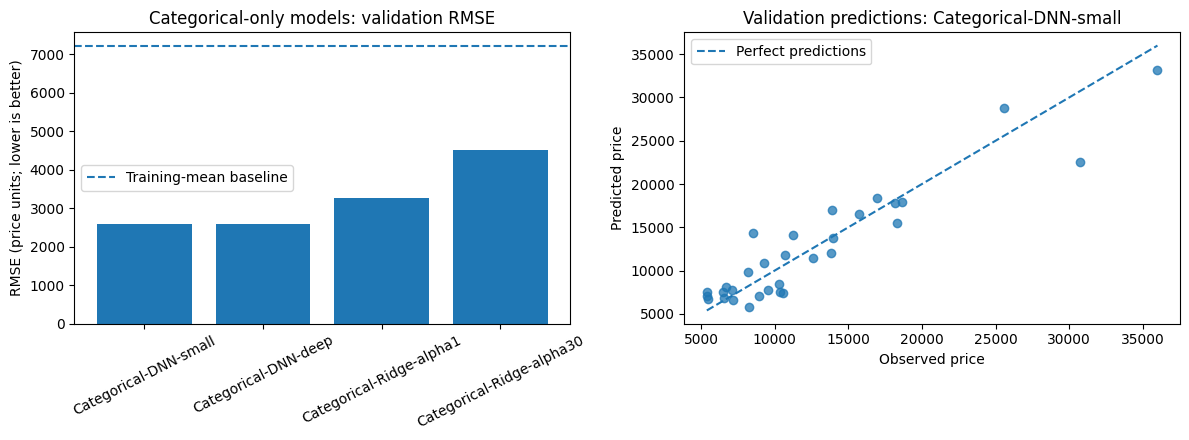

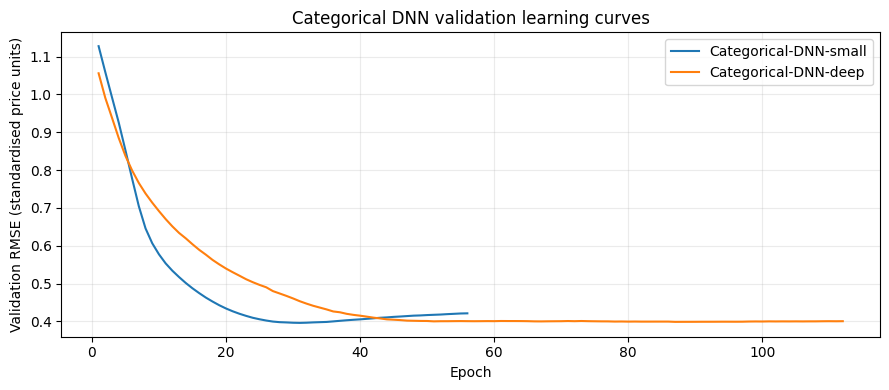

In [28]:
# Visualise validation errors and best categorical predictions
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(category_comparison['model'], category_comparison['validation_RMSE'])
axes[0].axhline(baseline_results['validation_RMSE'], linestyle='--',
                label='Training-mean baseline')
axes[0].set_title('Categorical-only models: validation RMSE')
axes[0].set_ylabel('RMSE (price units; lower is better)')
axes[0].tick_params(axis='x', rotation=27)
axes[0].legend()

best_cat_predictions = np.asarray(category_predictions[best_category_name])
axes[1].scatter(y_val, best_cat_predictions, alpha=0.75)
bounds = [min(float(y_val.min()), float(best_cat_predictions.min())),
          max(float(y_val.max()), float(best_cat_predictions.max()))]
axes[1].plot(bounds, bounds, linestyle='--', label='Perfect predictions')
axes[1].set_xlabel('Observed price')
axes[1].set_ylabel('Predicted price')
axes[1].set_title(f'Validation predictions: {best_category_name}')
axes[1].legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4))
for name, history in category_histories.items():
    # Validation losses are MSE in standardised-target units; sqrt makes RMSE.
    curves = np.sqrt(np.maximum(0.0, np.asarray(history.history['val_loss'])))
    plt.plot(np.arange(1, len(curves) + 1), curves, label=name)
plt.title('Categorical DNN validation learning curves')
plt.xlabel('Epoch')
plt.ylabel('Validation RMSE (standardised price units)')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Task 3 | Results and interpretation

The categorical-only experiment created **58 one-hot columns** from **10 original categorical inputs**. The best validation model was **Categorical-DNN-small** (RMSE **2,577.88**, MAE **2,020.09**, R² **0.87**), using an Adam-optimised network with one 16-unit hidden layer. The deeper network returned RMSE **2,595.51**. The shallow model took **8.44 s** compared with **15.38 s** for the deeper model in this particular run. With only 31 validation observations, these results cannot establish a reliable difference in generalisation.

For Ridge regression, a weaker penalty (**α=1**, RMSE **3,264.88**) outperformed a stronger penalty (**α=30**, RMSE **4,506.15**). The categorical-only DNN also scored below the best Task 1 numeric-only DNN (**3,668.77 RMSE**) on this validation split, but the architectures and target-handling procedures differ, so this is not a causal test of feature importance. Brand and other categories can act as proxies for price segments. Test-set prediction errors have **not** yet been assessed.

## Task 4 | Mixed numerical + categorical modelling

**Lab question:** What happens when **all 15 numerical variables** and **all 10 categorical variables** are combined? We will compare simple linear models, regularised linear models, two feedforward neural architectures, a **custom neural hybrid**, and a targeted feature-engineering ablation.

**Fairness and leakage controls**

- Use exactly the **same 139 training / 31 validation / 31 test split** as Tasks 0–3; do not use test outcomes for model selection.
- Reuse the **train-fitted numeric imputer / standardiser** and the **train-fitted categorical imputer / one-hot encoder** from earlier cells. Unknown validation categories get an all-zero encoded block.
- Ridge and ordinary linear regression predict prices in original units; neural networks train against a **train-fitted standardised price target** and convert their predictions back into original price units **before** reporting MAE / RMSE / R².
- Early stopping monitors validation loss (therefore validation is used for model selection); it is **not** a substitute for an independent test set.
- The custom `HybridPriceRegressor` is a subclassed Keras model with a linear skip connection and a nonlinear branch. Unlike a standard DNN, it adds both branch outputs; this is distinct from the deprecated `tf.estimator` API. Modern Keras implementations were approved by the lecturer.

In [29]:
# Combine all predictors using train-fitted preprocessing; evaluate on validation
# Task 2 created train-only-fitted numeric scaling; Task 3 created train-only-fitted one-hot encoding.
assert X_train_scaled.shape == (len(train_data), len(NUMERIC_FEATURES))
assert X_train_cat.shape[0] == len(train_data)
assert X_val_scaled.shape[0] == X_val_cat.shape[0] == len(validation_data)

X_train_mixed = np.concatenate([X_train_scaled, X_train_cat], axis=1).astype('float32')
X_val_mixed = np.concatenate([X_val_scaled, X_val_cat], axis=1).astype('float32')
mixed_feature_names = list(NUMERIC_FEATURES) + list(cat_encoded_names)

assert X_train_mixed.shape[1] == len(NUMERIC_FEATURES) + X_train_cat.shape[1]
assert X_train_mixed.shape[1] == X_val_mixed.shape[1] == len(mixed_feature_names)
assert np.isfinite(X_train_mixed).all() and np.isfinite(X_val_mixed).all()
assert len(y_train) == len(X_train_mixed) and len(y_val) == len(X_val_mixed)

print('Raw numeric predictors:', len(NUMERIC_FEATURES))
print('Raw categorical predictors:', len(CATEGORICAL_FEATURES))
print('One-hot columns:', X_train_cat.shape[1])
print('Final mixed input width:', X_train_mixed.shape[1])
print('Train / validation observations:', len(X_train_mixed), '/', len(X_val_mixed))


Raw numeric predictors: 15
Raw categorical predictors: 10
One-hot columns: 58
Final mixed input width: 73
Train / validation observations: 139 / 31


In [30]:
# A shared evaluation function, plus interpretable linear benchmarks
from sklearn.linear_model import LinearRegression, Ridge

mixed_results = []
mixed_models = {}
mixed_predictions = {}
mixed_histories = {}

def record_mixed_result(name, predictions, model_family, settings, seconds):
    """Report all model scores in ORIGINAL price units, with integrity checks."""
    predictions = np.asarray(predictions, dtype=float).reshape(-1)
    if predictions.shape != y_val.shape or not np.isfinite(predictions).all():
        raise ValueError(f'{name}: output shape mismatch or non-finite prediction')
    entry = {
        'model': name,
        'family': model_family,
        'settings': settings,
        'validation_MAE': float(mean_absolute_error(y_val, predictions)),
        'validation_RMSE': float(np.sqrt(mean_squared_error(y_val, predictions))),
        'validation_R2': float(r2_score(y_val, predictions)),
        'training_seconds': float(seconds),
    }
    mixed_results.append(entry)
    mixed_predictions[name] = predictions
    print(f'{name}: RMSE={entry["validation_RMSE"]:,.2f} '
          f'| MAE={entry["validation_MAE"]:,.2f} | R²={entry["validation_R2"]:.3f}')
    return entry

# LinearRegression is an interpretable reference, not necessarily the highest accuracy model.
# The ridge alpha values test the bias/variance trade-off on the same encoded predictors.
for name, estimator in [
    ('Mixed-Linear', LinearRegression()),
    ('Mixed-Ridge-alpha1', Ridge(alpha=1.0)),
    ('Mixed-Ridge-alpha10', Ridge(alpha=10.0)),
    ('Mixed-Ridge-alpha30', Ridge(alpha=30.0)),
]:
    start = time.perf_counter()
    estimator.fit(X_train_mixed, y_train)
    elapsed = time.perf_counter() - start
    prediction = estimator.predict(X_val_mixed)
    mixed_models[name] = estimator
    setting = 'ordinary least squares' if name == 'Mixed-Linear' else f'alpha={estimator.alpha:g}'
    record_mixed_result(name, prediction, 'linear', setting, elapsed)

Mixed-Linear: RMSE=2,714.84 | MAE=1,843.27 | R²=0.858
Mixed-Ridge-alpha1: RMSE=2,190.77 | MAE=1,684.68 | R²=0.908
Mixed-Ridge-alpha10: RMSE=2,088.33 | MAE=1,529.35 | R²=0.916
Mixed-Ridge-alpha30: RMSE=2,232.41 | MAE=1,583.10 | R²=0.904


In [31]:
# Two mixed-feature DNNs using an identical (train-fitted) target scale
# Scaling the labels assists optimisation; reported errors are inverse-transformed to prices.
assert np.allclose(category_y_train, price_standardizer.transform(y_train.reshape(-1, 1)).ravel())

MIXED_DNN_CONFIGS = [
    DNNConfig('Mixed-DNN-small', (16,), 'Adam', 0.002, 16, 200),
    DNNConfig('Mixed-DNN-deep', (32, 16), 'Adam', 0.001, 16, 200),
]

def build_mixed_dnn(config, input_width):
    """Construct a fresh Keras network for scaled numeric and encoded category data."""
    if config.optimizer != 'Adam':
        raise ValueError('Only Adam is specified for the controlled mixed-DNN trials.')
    layers = [keras.Input(shape=(input_width,))]
    layers += [keras.layers.Dense(count, activation='relu', kernel_initializer='he_normal')
               for count in config.hidden_units]
    layers.append(keras.layers.Dense(1, activation='linear'))
    estimator = keras.Sequential(layers, name=config.name.replace('-', '_'))
    estimator.compile(optimizer=keras.optimizers.Adam(learning_rate=config.learning_rate),
                      loss='mse', metrics=['mae'])
    return estimator

for cfg in MIXED_DNN_CONFIGS:
    keras.utils.set_random_seed(SEED)
    estimator = build_mixed_dnn(cfg, X_train_mixed.shape[1])
    stopper = keras.callbacks.EarlyStopping(monitor='val_loss', patience=25,
                                            restore_best_weights=True)
    start = time.perf_counter()
    history = estimator.fit(
        X_train_mixed, category_y_train,
        validation_data=(X_val_mixed, category_y_val),
        epochs=cfg.epochs, batch_size=cfg.batch_size,
        callbacks=[stopper], shuffle=True, verbose=0
    )
    elapsed = time.perf_counter() - start
    estimated_z = estimator.predict(X_val_mixed, verbose=0).reshape(-1, 1)
    estimated_price = price_standardizer.inverse_transform(estimated_z).ravel()
    mixed_models[cfg.name] = estimator
    mixed_histories[cfg.name] = history
    record_mixed_result(cfg.name, estimated_price, 'DNN',
                        f'hidden={cfg.hidden_units}; Adam lr={cfg.learning_rate}; '
                        f'batch={cfg.batch_size}; epochs_run={len(history.history["loss"])}',
                        elapsed)

Mixed-DNN-small: RMSE=3,112.96 | MAE=2,322.43 | R²=0.813
Mixed-DNN-deep: RMSE=2,641.66 | MAE=1,875.67 | R²=0.866


In [32]:
# Custom Keras regression architecture: a linear skip + nonlinear DNN
# Unlike a stock Sequential model, our subclass explicitly combines two fitted branches.
class HybridPriceRegressor(keras.Model):
    """Learn a global linear price component AND nonlinear interactions jointly."""
    def __init__(self, hidden_width=32, dropout_rate=0.10):
        super().__init__(name='Mixed_Custom_LinearPlusDNN')
        self.linear_component = keras.layers.Dense(1, name='linear_skip')
        self.hidden_1 = keras.layers.Dense(hidden_width, activation='relu')
        self.dropout = keras.layers.Dropout(dropout_rate)
        self.hidden_2 = keras.layers.Dense(16, activation='relu')
        self.nonlinear_component = keras.layers.Dense(1, name='nonlinear_head')

    def call(self, inputs, training=False):
        linear_prediction = self.linear_component(inputs)
        hidden = self.hidden_1(inputs)
        hidden = self.dropout(hidden, training=training)
        hidden = self.hidden_2(hidden)
        correction = self.nonlinear_component(hidden)
        return linear_prediction + correction

keras.utils.set_random_seed(SEED)
custom_model = HybridPriceRegressor(hidden_width=32, dropout_rate=0.10)
custom_model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                     loss='mse', metrics=['mae'])
custom_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=30,
                                            restore_best_weights=True)
custom_start = time.perf_counter()
custom_history = custom_model.fit(
    X_train_mixed, category_y_train,
    validation_data=(X_val_mixed, category_y_val),
    epochs=220, batch_size=16, callbacks=[custom_stop],
    shuffle=True, verbose=0,
)
custom_seconds = time.perf_counter() - custom_start
custom_predictions_z = custom_model.predict(X_val_mixed, verbose=0).reshape(-1, 1)
custom_price_predictions = price_standardizer.inverse_transform(custom_predictions_z).ravel()

mixed_models['Mixed-Custom-LinearPlusDNN'] = custom_model
mixed_histories['Mixed-Custom-LinearPlusDNN'] = custom_history
record_mixed_result('Mixed-Custom-LinearPlusDNN', custom_price_predictions,
                    'custom neural hybrid',
                    f'linear skip + Dense(32,16) + dropout=0.10; Adam lr=0.001; '
                    f'epochs_run={len(custom_history.history["loss"])}', custom_seconds)
print('Custom design: price = learned linear branch + learned nonlinear correction')


Mixed-Custom-LinearPlusDNN: RMSE=2,204.12 | MAE=1,785.64 | R²=0.906
Custom design: price = learned linear branch + learned nonlinear correction


### Task 4.1 | Feature-engineering ablation

Engine and vehicle-weight variables may exhibit **nonlinear interactions** with price. Create three physically interpretable numerical transformations, and test them in a **paired Ridge experiment with identical α**: base mixed inputs vs mixed inputs plus engineered columns. This isolates the effect of those added transformations under a common model and split (although the additional columns also change the model's dimensionality).

**Important:** Engineering functions never read `price`. Their standardiser is fitted only on training records. Use safe denominators and verify finite outputs. Improvement is an empirical question, **not** an assumption.

In [33]:
# Feature engineering WITHOUT target leakage; paired Ridge comparison
# X_train_raw/X_val_raw already contain TRAIN-median-imputed numeric predictors.
from sklearn.preprocessing import StandardScaler

def build_engineered_features(imputed_numeric):
    """Calculate dimensionally meaningful ratios using imputed numeric inputs only."""
    arr = np.asarray(imputed_numeric, dtype=float)
    columns = {name: position for position, name in enumerate(NUMERIC_FEATURES)}
    hp = arr[:, columns['horsepower']]
    mass_proxy = np.maximum(arr[:, columns['weight']], 1.0)  # curb-weight, not true mass
    displacement = arr[:, columns['engine-size']]
    length = np.maximum(arr[:, columns['length']], 1.0)
    width = np.maximum(arr[:, columns['width']], 1.0)
    return np.column_stack([
        1000.0 * hp / mass_proxy,       # power relative to reported curb-weight
        1000.0 * displacement / mass_proxy, # displacement relative to curb-weight
        length * width,                # approximate vehicle footprint
    ])

engineered_names = ['horsepower_per_1000_weight',
                    'engine_size_per_1000_weight', 'length_times_width']
engineered_train_raw = build_engineered_features(X_train_raw)
engineered_val_raw = build_engineered_features(X_val_raw)
assert np.isfinite(engineered_train_raw).all() and np.isfinite(engineered_val_raw).all()

engineered_scaler = StandardScaler()
engineered_train_scaled = engineered_scaler.fit_transform(engineered_train_raw)
engineered_val_scaled = engineered_scaler.transform(engineered_val_raw)
X_train_engineered = np.column_stack([X_train_mixed, engineered_train_scaled]).astype('float32')
X_val_engineered = np.column_stack([X_val_mixed, engineered_val_scaled]).astype('float32')

# Same regularisation strength and original-price target: the only deliberate difference
# between this paired experiment is the three additional engineered predictor columns.
for label, train_inputs, val_inputs in [
    ('Paired-Ridge-base-alpha1', X_train_mixed, X_val_mixed),
    ('Paired-Ridge-engineered-alpha1', X_train_engineered, X_val_engineered),
]:
    start = time.perf_counter()
    regressor = Ridge(alpha=1.0)
    regressor.fit(train_inputs, y_train)
    elapsed = time.perf_counter() - start
    mixed_models[label] = regressor
    record_mixed_result(label, regressor.predict(val_inputs), 'feature ablation',
                        'Ridge alpha=1; features=' + str(train_inputs.shape[1]), elapsed)

ablation_rows = [row for row in mixed_results if row['model'].startswith('Paired-Ridge-')]
ablation_table = pd.DataFrame(ablation_rows)[['model', 'validation_RMSE', 'validation_MAE', 'validation_R2']]
print('Added features:', engineered_names)
print('Engineered input shape:', X_train_engineered.shape)
display(ablation_table.round(2))
print('Engineered minus base validation RMSE:',
      f'{ablation_table.iloc[1]["validation_RMSE"] - ablation_table.iloc[0]["validation_RMSE"]:+,.2f}')

Paired-Ridge-base-alpha1: RMSE=2,190.77 | MAE=1,684.68 | R²=0.908
Paired-Ridge-engineered-alpha1: RMSE=2,178.83 | MAE=1,670.76 | R²=0.909
Added features: ['horsepower_per_1000_weight', 'engine_size_per_1000_weight', 'length_times_width']
Engineered input shape: (139, 76)


,model,validation_RMSE,validation_MAE,validation_R2
0,Paired-Ridge-base-alpha1,"2,190.77","1,684.68",0.91
1,Paired-Ridge-engineered-alpha1,"2,178.83","1,670.76",0.91


Engineered minus base validation RMSE: -11.94


In [34]:
# Rank the mixed-input candidates; compare them with earlier task results
mixed_comparison = pd.DataFrame(mixed_results).sort_values('validation_RMSE').reset_index(drop=True)
print('Task 4: all validation errors are expressed in original automobile price units.')
display(mixed_comparison.round(2))

best_mixed_name = str(mixed_comparison.iloc[0]['model'])
best_mixed_rmse = float(mixed_comparison.iloc[0]['validation_RMSE'])

full_task_comparison = pd.DataFrame([
    {'approach': 'Baseline: train-mean',
     'validation_RMSE': float(baseline_results['validation_RMSE'])},
    {'approach': 'Task 1: best raw-numeric DNN',
     'validation_RMSE': float(numeric_comparison.iloc[0]['validation_RMSE'])},
    {'approach': 'Task 2.2: standardised numeric inputs/target',
     'validation_RMSE': float(paired_target_table.loc[
         paired_target_table['input_representation']=='Standardised X / standardised y',
         'validation_RMSE'].iloc[0])},
    {'approach': 'Task 3: best categorical-only model',
     'validation_RMSE': float(category_comparison.iloc[0]['validation_RMSE'])},
    {'approach': 'Task 4: best mixed-feature model',
     'validation_RMSE': best_mixed_rmse},
]).sort_values('validation_RMSE')
print('Descriptive comparison: architectures and optimisation protocols are not fully matched.')
display(full_task_comparison.reset_index(drop=True).round(2))
print('Task 4 best VALIDATION model:', best_mixed_name)


Task 4: all validation errors are expressed in original automobile price units.


,model,family,settings,validation_MAE,validation_RMSE,validation_R2,training_seconds
0,Mixed-Ridge-alpha10,linear,alpha=10,"1,529.35","2,088.33",0.92,0.00
1,Paired-Ridge-engineered-alpha1,feature ablation,Ridge alpha=1; features=76,"1,670.76","2,178.83",0.91,0.00
2,Paired-Ridge-base-alpha1,feature ablation,Ridge alpha=1; features=73,"1,684.68","2,190.77",0.91,0.00
3,Mixed-Ridge-alpha1,linear,alpha=1,"1,684.68","2,190.77",0.91,0.00
4,Mixed-Custom-LinearPlusDNN,custom neural hybrid,"linear skip + Dense(32,16) + dropout=0.10; Ada...","1,785.64","2,204.12",0.91,4.84
5,Mixed-Ridge-alpha30,linear,alpha=30,"1,583.10","2,232.41",0.90,0.00
6,Mixed-DNN-deep,DNN,"hidden=(32, 16); Adam lr=0.001; batch=16; epoc...","1,875.67","2,641.66",0.87,13.45
7,Mixed-Linear,linear,ordinary least squares,"1,843.27","2,714.84",0.86,0.01
8,Mixed-DNN-small,DNN,"hidden=(16,); Adam lr=0.002; batch=16; epochs_...","2,322.43","3,112.96",0.81,3.26


Descriptive comparison: architectures and optimisation protocols are not fully matched.


,approach,validation_RMSE
0,Task 4: best mixed-feature model,"2,088.33"
1,Task 3: best categorical-only model,"2,577.88"
2,Task 1: best raw-numeric DNN,"3,668.77"
3,Task 2.2: standardised numeric inputs/target,"3,713.13"
4,Baseline: train-mean,"7,208.90"


Task 4 best VALIDATION model: Mixed-Ridge-alpha10


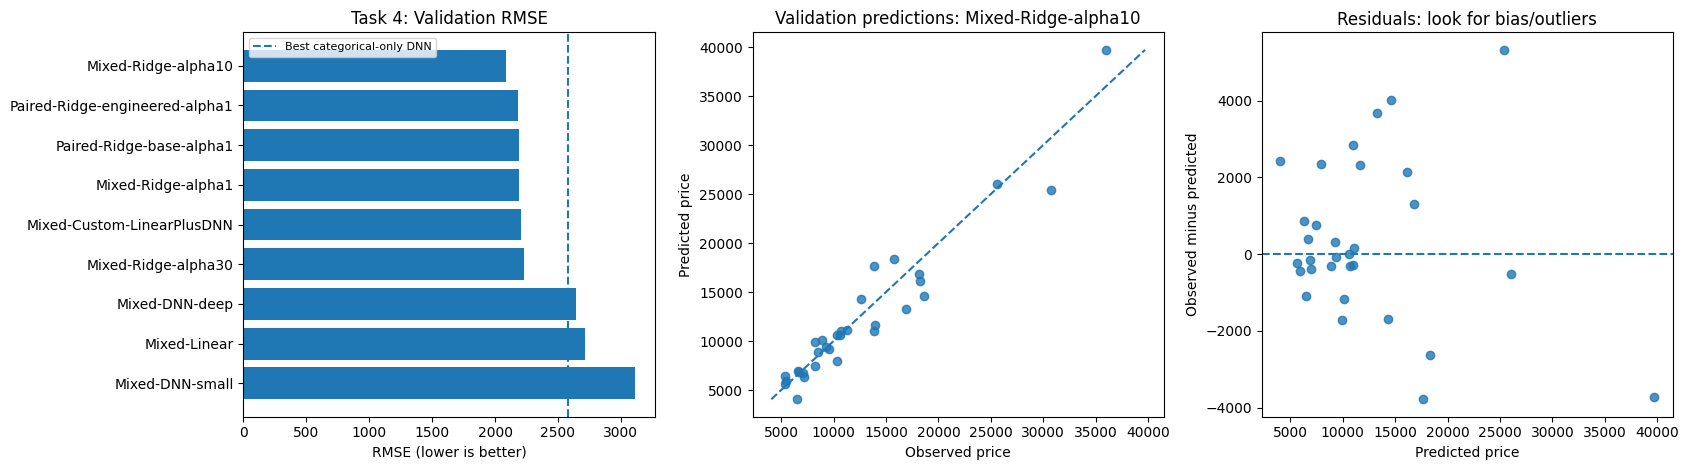

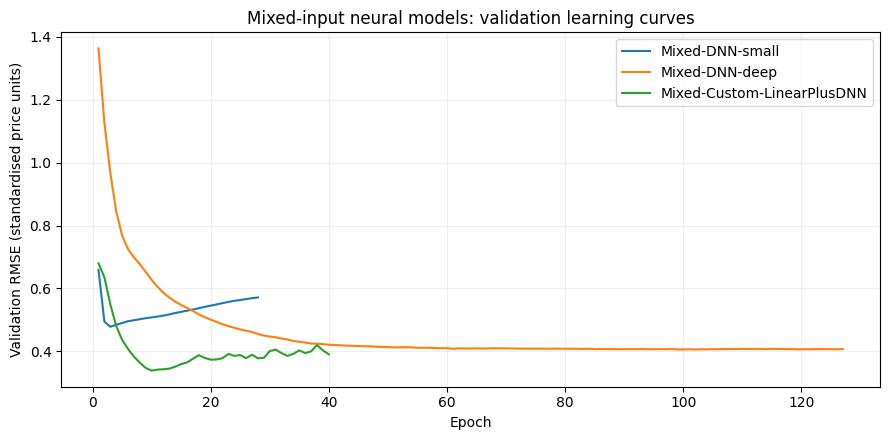

In [35]:
# Graphs: model errors, predicted vs observed values, and residuals
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
chart_rows = mixed_comparison.sort_values('validation_RMSE')
axes[0].barh(chart_rows['model'], chart_rows['validation_RMSE'])
axes[0].invert_yaxis()
axes[0].axvline(float(category_comparison.iloc[0]['validation_RMSE']),
                linestyle='--', label='Best categorical-only DNN')
axes[0].set_title('Task 4: Validation RMSE')
axes[0].set_xlabel('RMSE (lower is better)')
axes[0].legend(fontsize=8)

best_mixed_predictions = mixed_predictions[best_mixed_name]
price_bounds = [min(y_val.min(), best_mixed_predictions.min()),
                max(y_val.max(), best_mixed_predictions.max())]
axes[1].scatter(y_val, best_mixed_predictions, alpha=0.8)
axes[1].plot(price_bounds, price_bounds, linestyle='--')
axes[1].set_xlabel('Observed price')
axes[1].set_ylabel('Predicted price')
axes[1].set_title(f'Validation predictions: {best_mixed_name}')

residuals = y_val - best_mixed_predictions
axes[2].scatter(best_mixed_predictions, residuals, alpha=0.8)
axes[2].axhline(0, linestyle='--')
axes[2].set_xlabel('Predicted price')
axes[2].set_ylabel('Observed minus predicted')
axes[2].set_title('Residuals: look for bias/outliers')
plt.tight_layout()
plt.show()

# The following loss curves share the SAME train-fitted standardised target scale.
plt.figure(figsize=(9, 4.5))
for name, hist in mixed_histories.items():
    val_curve_z = np.sqrt(np.maximum(0, np.array(hist.history['val_loss'])))
    plt.plot(np.arange(1, len(val_curve_z)+1), val_curve_z, label=name)
plt.title('Mixed-input neural models: validation learning curves')
plt.xlabel('Epoch')
plt.ylabel('Validation RMSE (standardised price units)')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Task 4 | Results and interpretation

These are the **recorded validation** scores (139 training / 31 validation observations); small changes after rerunning neural networks are possible due to execution/backend differences.

- **Best mixed model:** Ridge regression (`alpha=10`), RMSE **2,088.33**, MAE **1,529.35**, R² **0.916**. Relative to the categorical-only DNN's RMSE **2,577.88**, this is **489.55 price units (19.0%) lower**. It also improves on the training-mean baseline RMSE **7,208.90** by about **71.0%**.
- **Regularisation:** mixed Ridge `alpha=1` (RMSE 2,190.77), `alpha=10` (2,088.33), and `alpha=30` (2,232.41) have a non-monotonic relationship; the moderate penalty was best **on this validation split**, not universally.
- **Neural alternatives:** mixed DNN-small RMSE 3,112.96 and DNN-deep RMSE 2,641.66; neither beats mixed Ridge `alpha=10` in this run. A more complex model was not automatically superior.
- **Custom architecture:** the implemented Keras `HybridPriceRegressor` learns a linear component and a nonlinear residual-like correction. Its RMSE **2,204.12** is competitive but **does not beat** Ridge `alpha=10`. This is a custom **Keras model**, not a legacy `tf.estimator` subclass.
- **Controlled feature engineering:** adding three physically motivated ratios/geometry features to the `alpha=1` Ridge model reduced validation RMSE **2,190.77 → 2,178.83** (difference **11.94**, about **0.5%**). This tiny change cannot establish a robust performance benefit.
- **Efficiency:** Ridge fit times printed as about 0.00–0.01 seconds are too small/rounded to support a precise speedup ratio, but neural training here took seconds. Timing depends on hardware and cannot be treated as a controlled benchmark.

**Plots:** the mixed small-DNN validation curve rises after an early low point, consistent with deterioration on validation data even while training continues. Ridge residuals cluster near zero for many cheaper vehicles, with several larger deviations for expensive vehicles; the small test/validation samples and price skew limit the strength of this pattern.

**Limitations:** only 201 priced vehicles; 139 original training rows; small 31-row validation and 31-row test portions; multiple configurations selected on one validation set; comparisons between Tasks 1–4 are descriptive because training/target-scaling choices also differ. Test errors have not been used in model selection up to this point. The final-stage cross-validation compares feature groups and penalties before reporting the reserved test-set performance.


---
## Additional evaluation | Cross-validation and independent test

**Purpose:** Before reporting a final result, assess whether the apparent `alpha=10` mixed-feature Ridge advantage survives multiple data folds.

**Fair comparison:** Five-fold cross-validation on the **170 development records only** (139 original training + 31 validation). Numeric-only, categorical-only and combined Ridge models use the **same folds**, with `alpha` values 0.1, 1, 3, 10, 30, 100. Every fold fits its **own** imputation, standardisation and one-hot encoding **only on that fold's training portion** through scikit-learn pipelines. Evaluation on held-out fold records uses RMSE, MAE and R² in **original price units**.

**Model-selection rule:** Choose the feature family and `alpha` with the smallest mean cross-validation RMSE (breaking any exact tie via smaller mean MAE). Refit that configuration on all 170 development records, then evaluate its predictive performance on the 31 held-out test rows. Also evaluate the trivial mean-price baseline on the same test rows to provide context. **Do not tune the model using test-set error metrics.**

*Why no DNN cross-validation here?* The early Tasks already supplied multiple DNN and custom-model experiments. The final small-data robustness screen considers an explicitly defined grid of six Ridge penalties across three feature groups. Consequently it cannot prove a Ridge model is universally better than all conceivable neural networks.


In [36]:
# Fold-safe preprocessing and an explicit cross-validation search
# This is additional evidence beyond the five compulsory Google tasks.
from sklearn.model_selection import KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge

DEVELOPMENT_FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
development_data = train_validation.copy()  # 170 rows; held-out TEST is NOT included.
assert len(development_data) == 170 and len(test_data) == 31
assert set(development_data.index).isdisjoint(test_data.index)

X_development = development_data[DEVELOPMENT_FEATURES].copy()
y_development = development_data[TARGET].to_numpy(dtype=float)
FOLDS = KFold(n_splits=5, shuffle=True, random_state=SEED)
ALPHA_GRID = (0.1, 1.0, 3.0, 10.0, 30.0, 100.0)
FEATURE_GROUPS = ('numerical', 'categorical', 'combined')


def create_ridge_pipeline(feature_group, alpha):
    """Create train-fold-only preprocessing followed by a Ridge regressor."""
    if feature_group not in FEATURE_GROUPS:
        raise ValueError(f'Unknown feature family: {feature_group}')
    if alpha <= 0:
        raise ValueError('Ridge alpha must be strictly positive.')

    transformers = []
    if feature_group in ('numerical', 'combined'):
        numeric_steps = Pipeline([
            ('impute_median', SimpleImputer(strategy='median')),
            ('standardise', StandardScaler()),
        ])
        transformers.append(('numeric', numeric_steps, NUMERIC_FEATURES))
    if feature_group in ('categorical', 'combined'):
        categorical_steps = Pipeline([
            ('impute_mode', SimpleImputer(strategy='most_frequent')),
            ('one_hot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ])
        transformers.append(('categorical', categorical_steps, CATEGORICAL_FEATURES))
    processor = ColumnTransformer(transformers=transformers, remainder='drop')
    return Pipeline([
        ('preprocessing', processor),
        ('regression', Ridge(alpha=float(alpha))),
    ])


cv_records = []
for family in FEATURE_GROUPS:
    for alpha in ALPHA_GRID:
        candidate = create_ridge_pipeline(family, alpha)
        scores = cross_validate(
            candidate, X_development, y_development,
            cv=FOLDS, n_jobs=1, error_score='raise',
            scoring={'rmse': 'neg_root_mean_squared_error',
                     'mae': 'neg_mean_absolute_error',
                     'r2': 'r2'},
        )
        fold_rmse = -scores['test_rmse']
        fold_mae = -scores['test_mae']
        cv_records.append({
            'feature_group': family,
            'alpha': float(alpha),
            'CV_RMSE_mean': float(fold_rmse.mean()),
            'CV_RMSE_std': float(fold_rmse.std(ddof=1)),
            'CV_MAE_mean': float(fold_mae.mean()),
            'CV_R2_mean': float(scores['test_r2'].mean()),
            'CV_fit_seconds_mean': float(scores['fit_time'].mean()),
            'fold_RMSE': ', '.join(f'{v:.1f}' for v in fold_rmse),
        })

cv_comparison = pd.DataFrame(cv_records).sort_values(
    ['CV_RMSE_mean', 'CV_MAE_mean'], ascending=[True, True]
).reset_index(drop=True)
assert len(cv_comparison) == len(FEATURE_GROUPS) * len(ALPHA_GRID)
assert cv_comparison['CV_RMSE_mean'].notna().all()
print('5-fold CV on development data ONLY:', len(development_data), 'rows')
print('Held-out test records seen by fitting/CV:', 0)
print('Ranked feature sets and Ridge penalties (lower CV RMSE = better):')
display(cv_comparison.round(2))


5-fold CV on development data ONLY: 170 rows
Held-out test records seen by fitting/CV: 0
Ranked feature sets and Ridge penalties (lower CV RMSE = better):


,feature_group,alpha,CV_RMSE_mean,CV_RMSE_std,CV_MAE_mean,CV_R2_mean,CV_fit_seconds_mean,fold_RMSE
0,combined,1.00,"2,312.42",307.66,"1,671.92",0.87,0.02,"2265.5, 2130.9, 2565.9, 1926.5, 2673.4"
1,combined,0.10,"2,343.47",219.88,"1,601.78",0.87,0.04,"2389.4, 1969.5, 2497.6, 2509.5, 2351.4"
2,combined,3.00,"2,379.21",381.13,"1,716.07",0.86,0.03,"2197.9, 2291.3, 2629.7, 1900.0, 2877.2"
3,combined,10.00,"2,484.07",442.47,"1,742.82",0.84,0.02,"2114.8, 2481.0, 2739.9, 2006.3, 3078.3"
4,categorical,0.10,"2,517.20",288.72,"1,829.44",0.83,0.02,"2925.9, 2669.6, 2299.5, 2209.8, 2481.1"
5,combined,30.00,"2,673.77",450.22,"1,804.61",0.82,0.02,"2241.9, 2654.6, 2947.2, 2246.1, 3279.0"
6,categorical,1.00,"2,824.26",275.05,"2,002.63",0.80,0.03,"3137.8, 2516.2, 2904.1, 2558.7, 3004.5"
7,numerical,10.00,"2,844.32",393.19,"2,036.19",0.79,0.01,"2615.9, 3018.1, 2985.9, 2294.8, 3306.9"
8,numerical,3.00,"2,868.95",324.99,"2,102.70",0.78,0.01,"2681.7, 3060.3, 2948.1, 2414.4, 3240.3"
9,numerical,1.00,"2,908.65",260.48,"2,145.95",0.78,0.01,"2715.6, 3083.5, 2956.0, 2577.1, 3211.0"


,feature_group,alpha,CV_RMSE_mean,CV_RMSE_std,CV_MAE_mean,CV_R2_mean,CV_fit_seconds_mean
0,combined,1.00,"2,312.42",307.66,"1,671.92",0.87,0.02
1,categorical,0.10,"2,517.20",288.72,"1,829.44",0.83,0.02
2,numerical,10.00,"2,844.32",393.19,"2,036.19",0.79,0.01


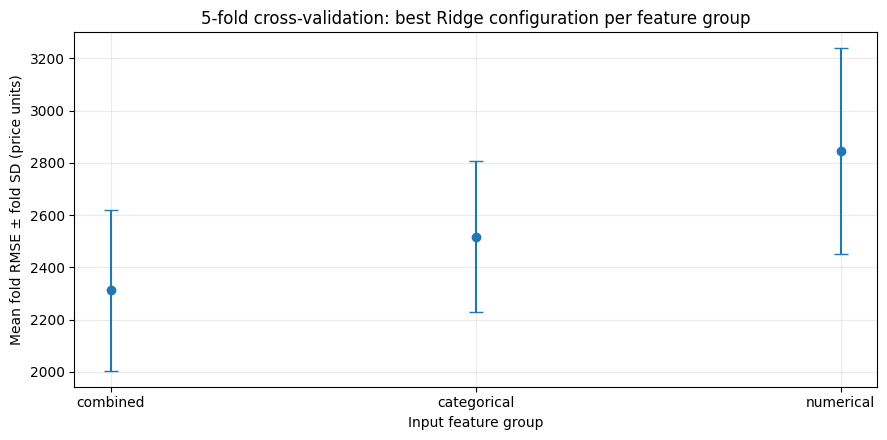

CV-selected model: combined Ridge, alpha=1
CV fold RMSE values: 2265.5, 2130.9, 2565.9, 1926.5, 2673.4


In [37]:
# Compare the strongest setting within each feature family
best_per_family = (
    cv_comparison.sort_values(['CV_RMSE_mean','CV_MAE_mean'])
    .drop_duplicates('feature_group', keep='first')
    .sort_values('CV_RMSE_mean')
    .reset_index(drop=True)
)
display(best_per_family[['feature_group', 'alpha', 'CV_RMSE_mean',
                         'CV_RMSE_std', 'CV_MAE_mean', 'CV_R2_mean',
                         'CV_fit_seconds_mean']].round(2))

plt.figure(figsize=(9, 4.5))
plt.errorbar(best_per_family['feature_group'], best_per_family['CV_RMSE_mean'],
             yerr=best_per_family['CV_RMSE_std'], fmt='o', capsize=5)
plt.title('5-fold cross-validation: best Ridge configuration per feature group')
plt.xlabel('Input feature group')
plt.ylabel('Mean fold RMSE ± fold SD (price units)')
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

chosen_family = str(cv_comparison.loc[0, 'feature_group'])
chosen_alpha = float(cv_comparison.loc[0, 'alpha'])
print(f'CV-selected model: {chosen_family} Ridge, alpha={chosen_alpha:g}')
print('CV fold RMSE values:', cv_comparison.loc[0, 'fold_RMSE'])



### Independent test evaluation

The next code cell refits the cross-validation-selected model on **170 development samples** and evaluates predictive error on **31 test samples**. Test-set descriptive statistics appeared in Task 0, but test prediction errors were not used to choose the model. Report the holdout results without retuning to them.


In [38]:
# Refit once on development rows; evaluate the held-out TEST rows
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

assert chosen_family in FEATURE_GROUPS and chosen_alpha in ALPHA_GRID
assert len(test_data) == 31
X_test_final = test_data[DEVELOPMENT_FEATURES].copy()
y_test_final = test_data[TARGET].to_numpy(dtype=float)

final_estimator = create_ridge_pipeline(chosen_family, chosen_alpha)
final_estimator.fit(X_development, y_development)
final_test_predictions = np.asarray(final_estimator.predict(X_test_final), dtype=float)

# Predict the mean of development labels (fair baseline on the same 31 observations).
final_baseline = DummyRegressor(strategy='mean')
final_baseline.fit(X_development, y_development)
final_baseline_predictions = final_baseline.predict(X_test_final)


def final_metrics(model_name, predictions):
    predictions = np.asarray(predictions, dtype=float).reshape(-1)
    if len(predictions) != len(y_test_final) or not np.isfinite(predictions).all():
        raise ValueError(f'{model_name}: invalid test predictions.')
    return {
        'model': model_name,
        'test_MAE': float(mean_absolute_error(y_test_final, predictions)),
        'test_RMSE': float(np.sqrt(mean_squared_error(y_test_final, predictions))),
        'test_R2': float(r2_score(y_test_final, predictions)),
    }

final_test_table = pd.DataFrame([
    final_metrics('Development-mean baseline', final_baseline_predictions),
    final_metrics(f'CV-selected {chosen_family} Ridge alpha={chosen_alpha:g}',
                  final_test_predictions),
])
print('One-time final holdout assessment, with refit on 170 development rows.')
print('Final feature family / Ridge penalty selected by CV:',
      chosen_family, chosen_alpha)
display(final_test_table.round(2))

base_test_rmse = float(final_test_table.iloc[0]['test_RMSE'])
model_test_rmse = float(final_test_table.iloc[1]['test_RMSE'])
print('RMSE change versus baseline:',
      f'{100 * (base_test_rmse-model_test_rmse)/base_test_rmse:+.1f}%')
print('Difference CV mean RMSE vs final test RMSE:',
      f'{model_test_rmse-float(cv_comparison.iloc[0]["CV_RMSE_mean"]):+,.2f}')



One-time final holdout assessment, with refit on 170 development rows.
Final feature family / Ridge penalty selected by CV: combined 1.0


,model,test_MAE,test_RMSE,test_R2
0,Development-mean baseline,"9,635.82","13,046.83",-0.20
1,CV-selected combined Ridge alpha=1,"2,107.81","3,339.60",0.92


RMSE change versus baseline: +74.4%
Difference CV mean RMSE vs final test RMSE: +1,027.17


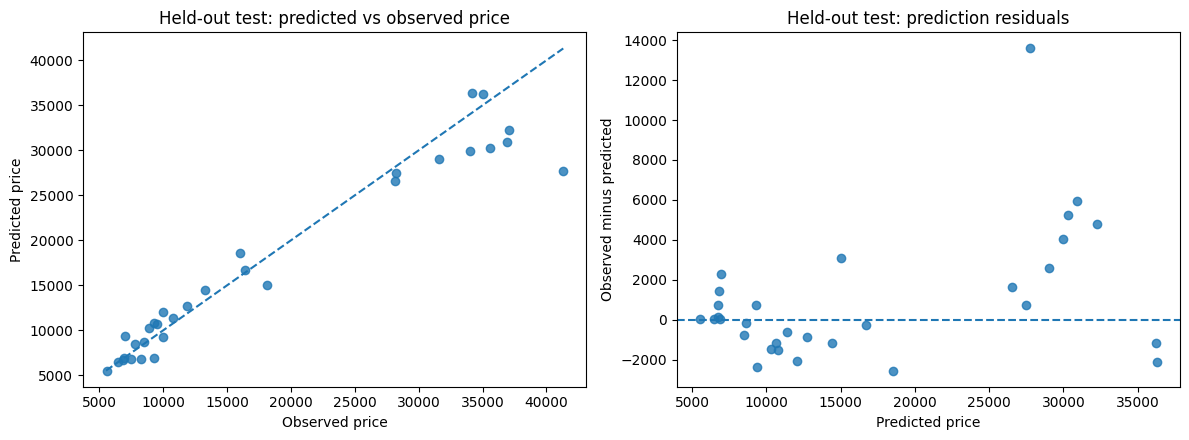

Largest three absolute test errors (not training examples):


,observed_price,predicted_price,absolute_error
1,"41,315.00","27,734.55","13,580.45"
21,"36,880.00","30,941.47","5,938.53"
9,"35,550.00","30,298.33","5,251.67"


Test size: 31 | Test mean: 17751.65 | Development mean: 12378.42


In [39]:
# Final diagnostic plots and transparent error examples
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
bounds = [min(y_test_final.min(), final_test_predictions.min()),
          max(y_test_final.max(), final_test_predictions.max())]
ax[0].scatter(y_test_final, final_test_predictions, alpha=0.8)
ax[0].plot(bounds, bounds, linestyle='--')
ax[0].set_title('Held-out test: predicted vs observed price')
ax[0].set_xlabel('Observed price')
ax[0].set_ylabel('Predicted price')

final_residuals = y_test_final - final_test_predictions
ax[1].scatter(final_test_predictions, final_residuals, alpha=0.8)
ax[1].axhline(0, linestyle='--')
ax[1].set_title('Held-out test: prediction residuals')
ax[1].set_xlabel('Predicted price')
ax[1].set_ylabel('Observed minus predicted')
plt.tight_layout()
plt.show()

final_diagnostics = pd.DataFrame({
    'observed_price': y_test_final,
    'predicted_price': final_test_predictions,
    'absolute_error': np.abs(final_residuals),
})
print('Largest three absolute test errors (not training examples):')
display(final_diagnostics.nlargest(3, 'absolute_error').round(2))
print('Test size:', len(y_test_final),
      '| Test mean:', round(float(y_test_final.mean()),2),
      '| Development mean:', round(float(y_development.mean()),2))


## Final evaluation | Results and limitations

**Five-fold cross-validation (170 development samples)**

| Model family and penalty | Mean fold RMSE | Fold SD | Mean fold MAE | Mean fold R² |
|---|---:|---:|---:|---:|
| **Combined Ridge, α=1** | **2,312.42** | **307.66** | **1,671.92** | **0.87** |
| Categorical Ridge, α=0.1 | 2,517.20 | 288.72 | 1,829.44 | 0.83 |
| Numerical Ridge, α=10 | 2,844.32 | 393.19 | 2,036.19 | 0.79 |

Eighteen Ridge configurations were compared under the same five folds, with imputation, numeric standardisation and categorical encoding refitted separately inside every training fold. The best cross-validated configuration was **combined Ridge α=1**. Earlier, **combined Ridge α=10** was strongest on one 31-row validation subset (RMSE 2,088.33); the changed ranking demonstrates the sensitivity of a small holdout to sample composition.

**31-row held-out test set (not used for model selection)**

| Model | Test MAE | Test RMSE | Test R² |
|---|---:|---:|---:|
| Development-mean baseline | 9,635.82 | 13,046.83 | -0.20 |
| **Combined Ridge α=1** | **2,107.81** | **3,339.60** | **0.92** |

Test RMSE is **74.4% lower** than the mean-price baseline but **1,027.17 price units (~44.4%) higher** than the winning model's mean CV RMSE. One high-price car (actual price **41,315.00**) was underestimated at **27,734.55**, an absolute error of **13,580.45**. The test subset's mean price (**17,751.65**) was inspected descriptively in Task 0 and is higher than the development subset's mean (**12,378.42**); this difference may contribute to, but does not prove the cause of, larger test errors.

**Evidence limits:** The original data contains only **201 priced cars**. Test-set price summaries were inspected in Task 0, although no test-set prediction errors informed training or model selection. Early DNN and hybrid experiments used the single validation split and may vary on rerun. The final five-fold search compares **Ridge candidates only**, not every neural model. Therefore the final test supports the selected Ridge model's predictive utility, but does not establish that it is globally optimal.

**Implementation:** The original laboratory uses the legacy TensorFlow Estimator API. This notebook uses Keras and scikit-learn equivalents, as permitted by the lecturer, and documents the model configurations and comparisons.

### Sources

- Google LLC. (2018). *Intro to modeling* [Jupyter notebook]. https://colab.research.google.com/github/google/eng-edu/blob/master/ml/fe/exercises/intro_to_modeling.ipynb
- Schlimmer, J. (1985). *Automobile* [Data set]. UCI Machine Learning Repository. https://doi.org/10.24432/C5B01C
- TensorFlow. (2024). *What's new in TensorFlow 2.16*. https://blog.tensorflow.org/2024/03/whats-new-in-tensorflow-216.html


